# Run SDM for Snowdon Beetle (*Chrysolina cerealis*): Logistic Regression

*Section 11 — Case study: species distribution modelling, notebook 2 of 5.* Previous: `01_prepare_datasets`. Next: `03_maxent_species_distribution_modelling`.

Now you have prepared the data layers, the next stage is to run a species distribution model (SDM) with the `rsgispy.modelling.species_distribution` module and a scikit-learn logistic regression. The workflow follows the rsgispy species distribution modelling guide, which uses the same data with a random forest.

**The species.** The Snowdon beetle lives only on wild thyme (*Thymus polytrichus*), on base-rich ledges, crags, scree and thyme-rich grassland of the high ground around Yr Wyddfa, where the thyme escapes grazing by sheep and goats. The 2015–2016 NRW surveys found it only between 555 and 827 m, and it may be retreating upslope (see notebook 01).

**What the model estimates.** We only have records of where the beetle *was* found (presences), not of where it was looked for and not found. The model therefore compares the presences with *pseudo-absences*, points drawn at random from the study area that describe the environment available to the beetle. The output is a **relative habitat suitability** from 0 to 1, high where the environment resembles that of the presences more than that of the study area as a whole; it is **not** the probability that the beetle occurs in a pixel, which would need to know how common the beetle is (its prevalence). In niche terms, the model describes the part of the beetle's **realised** niche that our variables can express: the conditions where it has been recorded, limited by grazing, dispersal and history as well as by its physiology, and seen only through the variables we chose (proxies for thyme and for refuges from grazing), at 20 m resolution, within this study area.

**Assumptions** to keep in mind when reading the results: the beetle is in equilibrium with its environment (it occupies most of the suitable places it can reach); the records are a representative sample of the places it occupies (no strong survey bias); and the variables describe the environment at a scale relevant to the beetle.

**You will learn:**
- how to explore the spatial structure of the records (`rsgispy.vector.stats.calc_correlogram`) and generate pseudo-absences;
- how to check collinearity with a correlation matrix and variance inflation factors (`calc_vif_multicollinearity`) and select variables;
- how to give a logistic regression a unimodal (quadratic) response inside a scikit-learn `Pipeline`;
- how to tune and evaluate a model honestly: spatial block cross-validation (`rsgispy.ml.cv.SpatialBlockKFold`), AUC, TSS and the Boyce index (`calc_sdm_eval_metrics`), null models (`calc_null_model_auc`) and residual autocorrelation (`calc_residual_autocorrelation`);
- how to interpret the model with response curves, jackknife variable importance, SHAP and Sobol sensitivity analysis, and what they say about the beetle's niche;
- how to predict an ensemble with uncertainty, threshold it, check where it extrapolates (`calc_mess`, `calc_exdet`) and project it to a warmer climate (`copy_env_vars_for_scenario`, `calc_range_change`).

**Before you start:** run `01_prepare_datasets` (it creates the cleaned presences, the valid-data mask and the habitat distance images in `outputs/`). Classification is introduced in section 4 (`04_image_classification`) and feature selection in section 5 (`05_regression/02_feature_selection`).

**Data:** from notebook 01: `outputs/Chrysolina_cerealis_presences.gpkg`, `outputs/valid_mask.tif`, `outputs/sdm_candidate_vars.json` and the images it lists (`../data/sdm/environmental_data/Elevation.tif`, `Mean_Winter_Temp.tif` and `outputs/phase1_dist_imgs/*.tif`).

**Run time:** about 2 minutes.

> **RSGISLib users:** the RSGISLib tutorial used a stand-alone `species_distribution.py` module; its functions are now part of rsgispy as `rsgispy.modelling.species_distribution` (`salib_sklearn_mdl_sensitity` is spelt `salib_sklearn_mdl_sensitivity` and the `calc_img_stats` argument of the prediction functions is `calc_stats`).

## Import Modules

In [1]:
import importlib.util
import os

import geopandas
import matplotlib.pyplot as plt
import numpy
import pandas
import rasterio
import rsgispy
import rsgispy.imagecalc.maths
import rsgispy.mapping.raster
import rsgispy.modelling.species_distribution as species_distribution
import rsgispy.tools.jsonio
import rsgispy.tools.plotting
import rsgispy.vector.stats
from IPython.display import Image, display
from rsgispy.ml.cv import SpatialBlockKFold
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

%matplotlib inline
pandas.set_option("display.max_columns", None)
pandas.set_option("display.width", 200)

## Create Output Data Directories

GeoTIFF outputs are compressed (DEFLATE) by default in rsgispy, so no environment set-up is needed.

In [2]:
out_dir = "outputs/sdm_LogReg_outs"
plots_dir = os.path.join(out_dir, "plots")
os.makedirs(plots_dir, exist_ok=True)
tmp_dir = "outputs/tmp_dir"
os.makedirs(tmp_dir, exist_ok=True)

## Define Input Data Files

The candidate variables are those chosen in notebook 01 from the ecology of the beetle: elevation, mean winter temperature, and the distances to six habitat groups.

In [3]:
presences_vec_file = "outputs/Chrysolina_cerealis_presences.gpkg"
presences_vec_lyr = "presences"
valid_msk_img = "outputs/valid_mask.tif"
cand_var_imgs = rsgispy.tools.jsonio.read_json_to_dict("outputs/sdm_candidate_vars.json")

env_vars = dict()
for var_name, img_file in cand_var_imgs.items():
    env_vars[var_name] = species_distribution.EnvVarInfo(
        name=var_name,
        file=img_file,
        band=1,
        data_type=rsgispy.VAR_TYPE_CONTINUOUS,
    )
list(env_vars)

['calc_grass_dist',
 'elevation',
 'flush_dist',
 'impr_grass_dist',
 'ledges_dist',
 'rock_dist',
 'scree_dist',
 'winter_temp']

## 1. Create Pseudo-Absences

We only have presence records, so pseudo-absences (also called background points) are randomly sampled within the valid-data mask. Three choices matter:

* **How many?** For regression models such as logistic regression, many pseudo-absences (around 10 000) describe the available environment best, and the presences and pseudo-absences are then given equal total weight in the fit (Barbet-Massin et al. 2012), here with `class_weight="balanced"` (section 5). With only 1000, the pseudo-absences would sample the environment of the study area less completely, and the fitted responses would depend more on which points happened to be drawn.
* **Exclusion distance** (`presence_smpls_dist_thres`). Pseudo-absences within 40 m (2 pixels) of a presence are rejected, so that no pseudo-absence lands in the same pixel as, or next to, a presence (contradictory training data). Much larger buffers (hundreds of metres or more) would remove the most suitable habitat around the known sites from the background, which makes the presences artificially easy to separate and inflates the evaluation scores.
* **Sampling bias.** The records come from naturalists and surveyors searching known crags and thyme patches on Yr Wyddfa, so the less accessible or less famous crags are probably under-recorded. Uniform random pseudo-absences assume every part of the study area was equally likely to be searched, so the model may partly learn where people looked. rsgispy can correct for this with a *bias grid* of survey effort, usually made from records of related species collected in the same way ("target-group" records): `create_bias_grid` makes the grid, and it can be used to draw the pseudo-absences in proportion to effort (`gen_pseudo_absences_smpls(..., bias_img=...)`), as a covariate held constant when predicting (`fixed_var_vals`), or as inverse-effort sample weights (`calc_bias_weights`). The tutorial data has **no target-group records**, and inventing an effort surface would be no better than ignoring the bias, so we do not correct for it here. Keep in mind that this is a limitation of the model; see the "Sampling bias" section of the guide for the code.

A random seed is set so the results are repeatable.

In [4]:
pseudo_abs_vec_file = os.path.join(out_dir, "pseudo_absences.gpkg")
pseudo_abs_vec_lyr = "pseudo_absences"
species_distribution.gen_pseudo_absences_smpls(
    in_msk_img=valid_msk_img,
    img_msk_val=1,
    out_vec_file=pseudo_abs_vec_file,
    out_vec_lyr=pseudo_abs_vec_lyr,
    n_smpls=10000,
    xtra_n_smpls=5000,
    presence_smpls_vec_file=presences_vec_file,
    presence_smpls_vec_lyr=presences_vec_lyr,
    presence_smpls_dist_thres=40,
    out_format="GPKG",
    rnd_seed=42,
    use_pbar=False,
)

## 2. Extract the Environmental Variables and Combine the Samples

`extract_env_var_data` adds a column for each variable with the value of the pixel under each point; points on no data get `-9999` and are removed. `combine_presence_absence_data` stacks the presences (`clsid` = 1) and pseudo-absences (`clsid` = 0) into one layer.

In [5]:
analysis_vars = list(env_vars)
pres_gdf = species_distribution.extract_env_var_data(
    env_vars, presences_vec_file, presences_vec_lyr, out_no_data_val=-9999, use_pbar=False
)
abs_gdf = species_distribution.extract_env_var_data(
    env_vars, pseudo_abs_vec_file, pseudo_abs_vec_lyr, out_no_data_val=-9999, use_pbar=False
)
pres_gdf = pres_gdf[(pres_gdf[analysis_vars] != -9999).all(axis=1)]
abs_gdf = abs_gdf[(abs_gdf[analysis_vars] != -9999).all(axis=1)]
print(f"{len(pres_gdf)} presences and {len(abs_gdf)} pseudo-absences")

samples_vec_file = os.path.join(out_dir, "sdm_samples.gpkg")
samples_vec_lyr = "samples"
analysis_vars = species_distribution.combine_presence_absence_data(
    pres_gdf,
    None,
    abs_gdf,
    None,
    env_vars,
    out_vec_file=samples_vec_file,
    out_vec_lyr=samples_vec_lyr,
    out_format="GPKG",
    cls_col="clsid",
)
samples_gdf = geopandas.read_file(samples_vec_file, layer=samples_vec_lyr)
analysis_vars

34 presences and 10000 pseudo-absences


['calc_grass_dist',
 'elevation',
 'flush_dist',
 'impr_grass_dist',
 'ledges_dist',
 'rock_dist',
 'scree_dist',
 'winter_temp']

## 3. Explore the Data: How Do the Presences Differ from the Study Area?

Before fitting a model, compare the values of each variable at the presences with those at the pseudo-absences (the study area as a whole). A variable whose distributions overlap completely is unlikely to help; one where they differ tells us something about where the beetle lives. (`species_distribution.comparison_box_plots` writes the same comparison as one image per variable; here we draw all eight in one figure.)

clsid,median pseudo-absence,median presence
calc_grass_dist,1405.56,1555.63
elevation,429.72,673.02
flush_dist,412.31,1041.75
impr_grass_dist,1201.17,1800.75
ledges_dist,1727.43,402.48
rock_dist,1807.54,2519.20
scree_dist,744.31,581.55
winter_temp,3.22,2.87


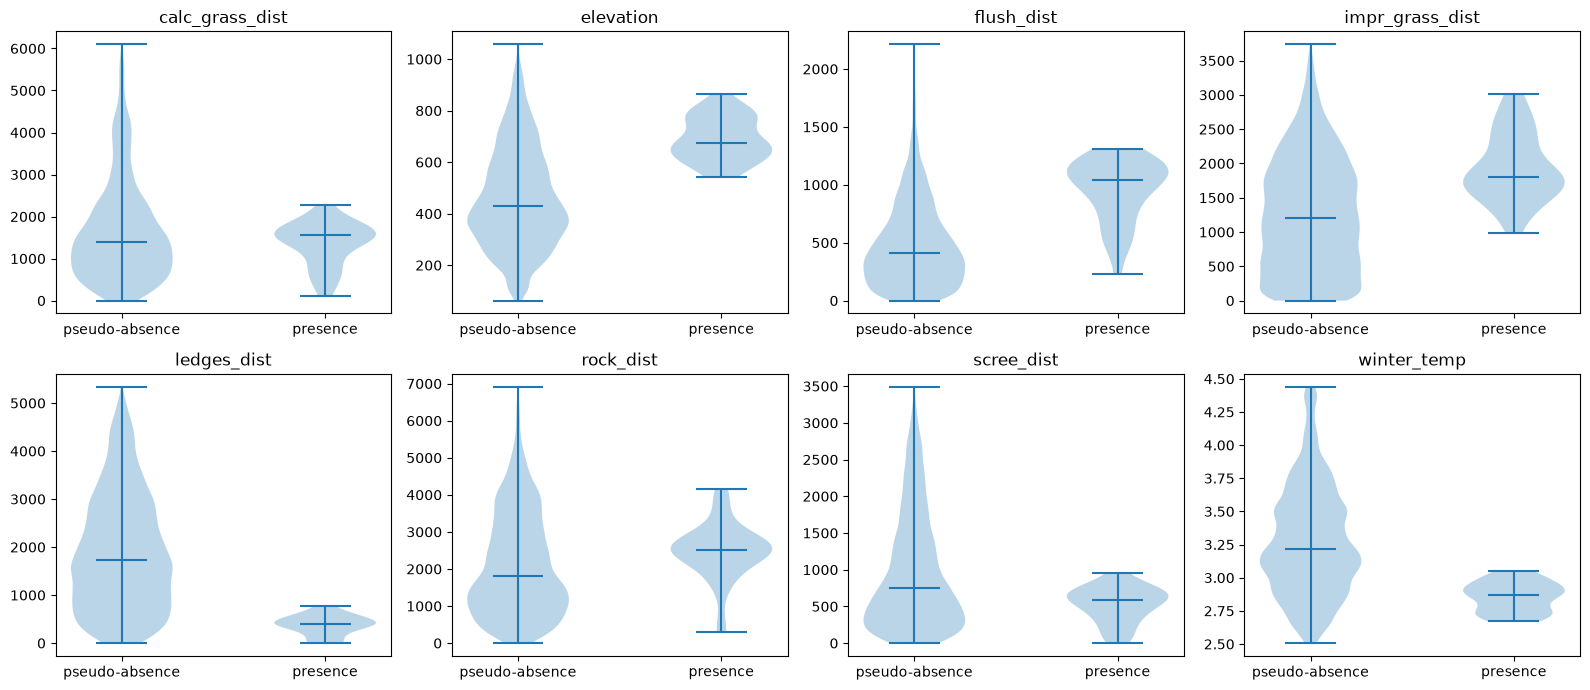

In [6]:
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, var_name in zip(axs.flatten(), analysis_vars):
    vals = [
        samples_gdf.loc[samples_gdf["clsid"] == 0, var_name],
        samples_gdf.loc[samples_gdf["clsid"] == 1, var_name],
    ]
    ax.violinplot(vals, showmedians=True)
    ax.set_xticks([1, 2], ["pseudo-absence", "presence"])
    ax.set_title(var_name)
fig.tight_layout()

samples_gdf.groupby("clsid")[analysis_vars].median().T.rename(
    columns={0: "median pseudo-absence", 1: "median presence"}
).round(2)

The presences differ from the study area as a whole in several ways:

* **Elevation and temperature.** The presences are higher (median 673 m against 430 m) and colder (2.87 °C against 3.22 °C), within a narrow band: 543–864 m and 2.67–3.05 °C, close to the 555–827 m of the NRW surveys. Neither the warm valleys nor the very highest ground have records.
* **Ledges.** Every presence is within about 780 m of mapped species-rich ledges (median 402 m), against a median of 1727 m for the study area: the clearest habitat signal, as expected for a beetle that depends on thyme on ledges.
* **Improved grassland** is further from the presences (median 1801 m against 1201 m), as expected for an avoided habitat (it is also in the valleys, i.e. warm).
* **Flushes** are *further* from the presences (median 1042 m against 412 m), the opposite of the "base-rich flush" idea of notebook 01, but consistent with thyme's need for free-draining ground: the beetle's sites are on dry crag ledges and slopes, not on the wet, gentler ground where flushes are mapped.
* **Rock exposures** are also further from the presences (2519 m against 1808 m). On Yr Wyddfa the crags with the beetle are mapped as ledges and scree, while most polygons mapped as "rock exposure" are elsewhere.
* **Scree** is only slightly closer to the presences (582 m against 744 m), and **calcareous grassland** shows no difference (1556 m against 1406 m): the tiny areas mapped as calcareous grassland and basic heath mosaic are not where the beetle is, probably because thyme-rich grassland on Snowdon occurs in patches too small to map at the scale of the Phase 1 survey.

So the data support some of the hypotheses of notebook 01 (ledges, temperature, avoidance of improved grassland), contradict one (flushes), and do not support others (rock, calcareous grassland). We keep all the variables for now; the model and the interpretation tools will show which matter once the others are accounted for.

## 4. Spatial Structure of the Records

Species records are rarely independent: they cluster around a few well-known sites, and environmental values are similar at nearby points (spatial autocorrelation). This matters for evaluation: if test points are next to training points, a model can score well without having learnt anything that transfers to new places.

First, how clustered are the presences? Then a Moran's I **correlogram** (`calc_correlogram`) of a covariate at all the samples shows the distance over which values are similar: Moran's I is the correlation between the values of pairs of points in each distance class, and the distance at which it falls to its expectation (about 0) is the range of the autocorrelation.

In [7]:
pres_xy = numpy.column_stack([pres_gdf.geometry.x, pres_gdf.geometry.y])
pair_dists = numpy.sqrt(((pres_xy[:, None, :] - pres_xy[None, :, :]) ** 2).sum(axis=2))
nn_dists = numpy.where(numpy.eye(len(pres_xy), dtype=bool), numpy.inf, pair_dists).min(axis=1)
print(f"Nearest neighbour distance between presences: median {numpy.median(nn_dists):.0f} m")
print(f"Presences within 2 km of the median presence location: "
      f"{(numpy.hypot(*(pres_xy - numpy.median(pres_xy, axis=0)).T) <= 2000).sum()} of {len(pres_xy)}")

dist_classes = [0, 250, 500, 1000, 1500, 2000, 3000, 4000, 6000]
for var_name in ["winter_temp", "ledges_dist"]:
    corr_df = rsgispy.vector.stats.calc_correlogram(
        samples_gdf,
        None,
        var_name,
        dist_classes=dist_classes,
        n_perms=99,
        rnd_seed=42,
        plot_file=os.path.join(plots_dir, f"correlogram_{var_name}.png"),
    )
    print(var_name)
    print(corr_df[["dist_lower", "dist_upper", "n_pairs", "morans_i", "p_value"]].round(3))

Nearest neighbour distance between presences: median 152 m
Presences within 2 km of the median presence location: 30 of 34


winter_temp
   dist_lower  dist_upper     n_pairs  morans_i  p_value
0         0.0       250.0    114086.0     0.970     0.01
1       250.0       500.0    336348.0     0.891     0.01
2       500.0      1000.0   1291330.0     0.704     0.01
3      1000.0      1500.0   2056314.0     0.453     0.01
4      1500.0      2000.0   2733626.0     0.241     0.01
5      2000.0      3000.0   7157028.0     0.031     0.01
6      3000.0      4000.0   8855454.0    -0.046     0.01
7      4000.0      6000.0  20518002.0    -0.009     0.01


ledges_dist
   dist_lower  dist_upper     n_pairs  morans_i  p_value
0         0.0       250.0    114086.0     0.995     0.01
1       250.0       500.0    336348.0     0.975     0.01
2       500.0      1000.0   1291330.0     0.910     0.01
3      1000.0      1500.0   2056314.0     0.793     0.01
4      1500.0      2000.0   2733626.0     0.653     0.01
5      2000.0      3000.0   7157028.0     0.431     0.01
6      3000.0      4000.0   8855454.0     0.158     0.01
7      4000.0      6000.0  20518002.0    -0.104     0.01


The presences are strongly clustered: the median distance from a presence to its nearest neighbour is 152 m, and 30 of the 34 are within 2 km of the middle of the cluster on Yr Wyddfa.

The correlograms show that the covariates are spatially autocorrelated over long distances: Moran's I for winter temperature is 0.97 between points less than 250 m apart, falls to 0.24 at 1.5–2 km and to about 0 beyond 3 km; for the distance to ledges it is still 0.43 at 2–3 km and only reaches 0 at about 4 km. (With 10 000 points there are millions of pairs, so even tiny values of I are "significant", p = 0.01; look at the size of I, not the p-value.)

This tells us how far apart training and test points must be to be (nearly) independent: about 3–4 km. In section 9 we will see that with records this clustered we cannot use blocks that large.

## 5. Check Collinearity and Select the Variables

Strongly correlated variables carry the same information. In a regression they make the coefficients unstable (the effect can be shared between the two in many ways), split their importance, and make response curves hard to interpret; and the model becomes unreliable when it is applied where the correlation is different (e.g. a future climate). Two checks:

* the **correlation matrix** (Pearson r between each pair of variables);
* the **variance inflation factor** (VIF, `calc_vif_multicollinearity`): how well each variable is predicted by *all* the others together, which also catches collinearity among combinations of variables. Common rules of thumb are to keep only one variable of each pair with |r| > 0.7 and to remove variables until every VIF is below 10 (5 for a stricter check).

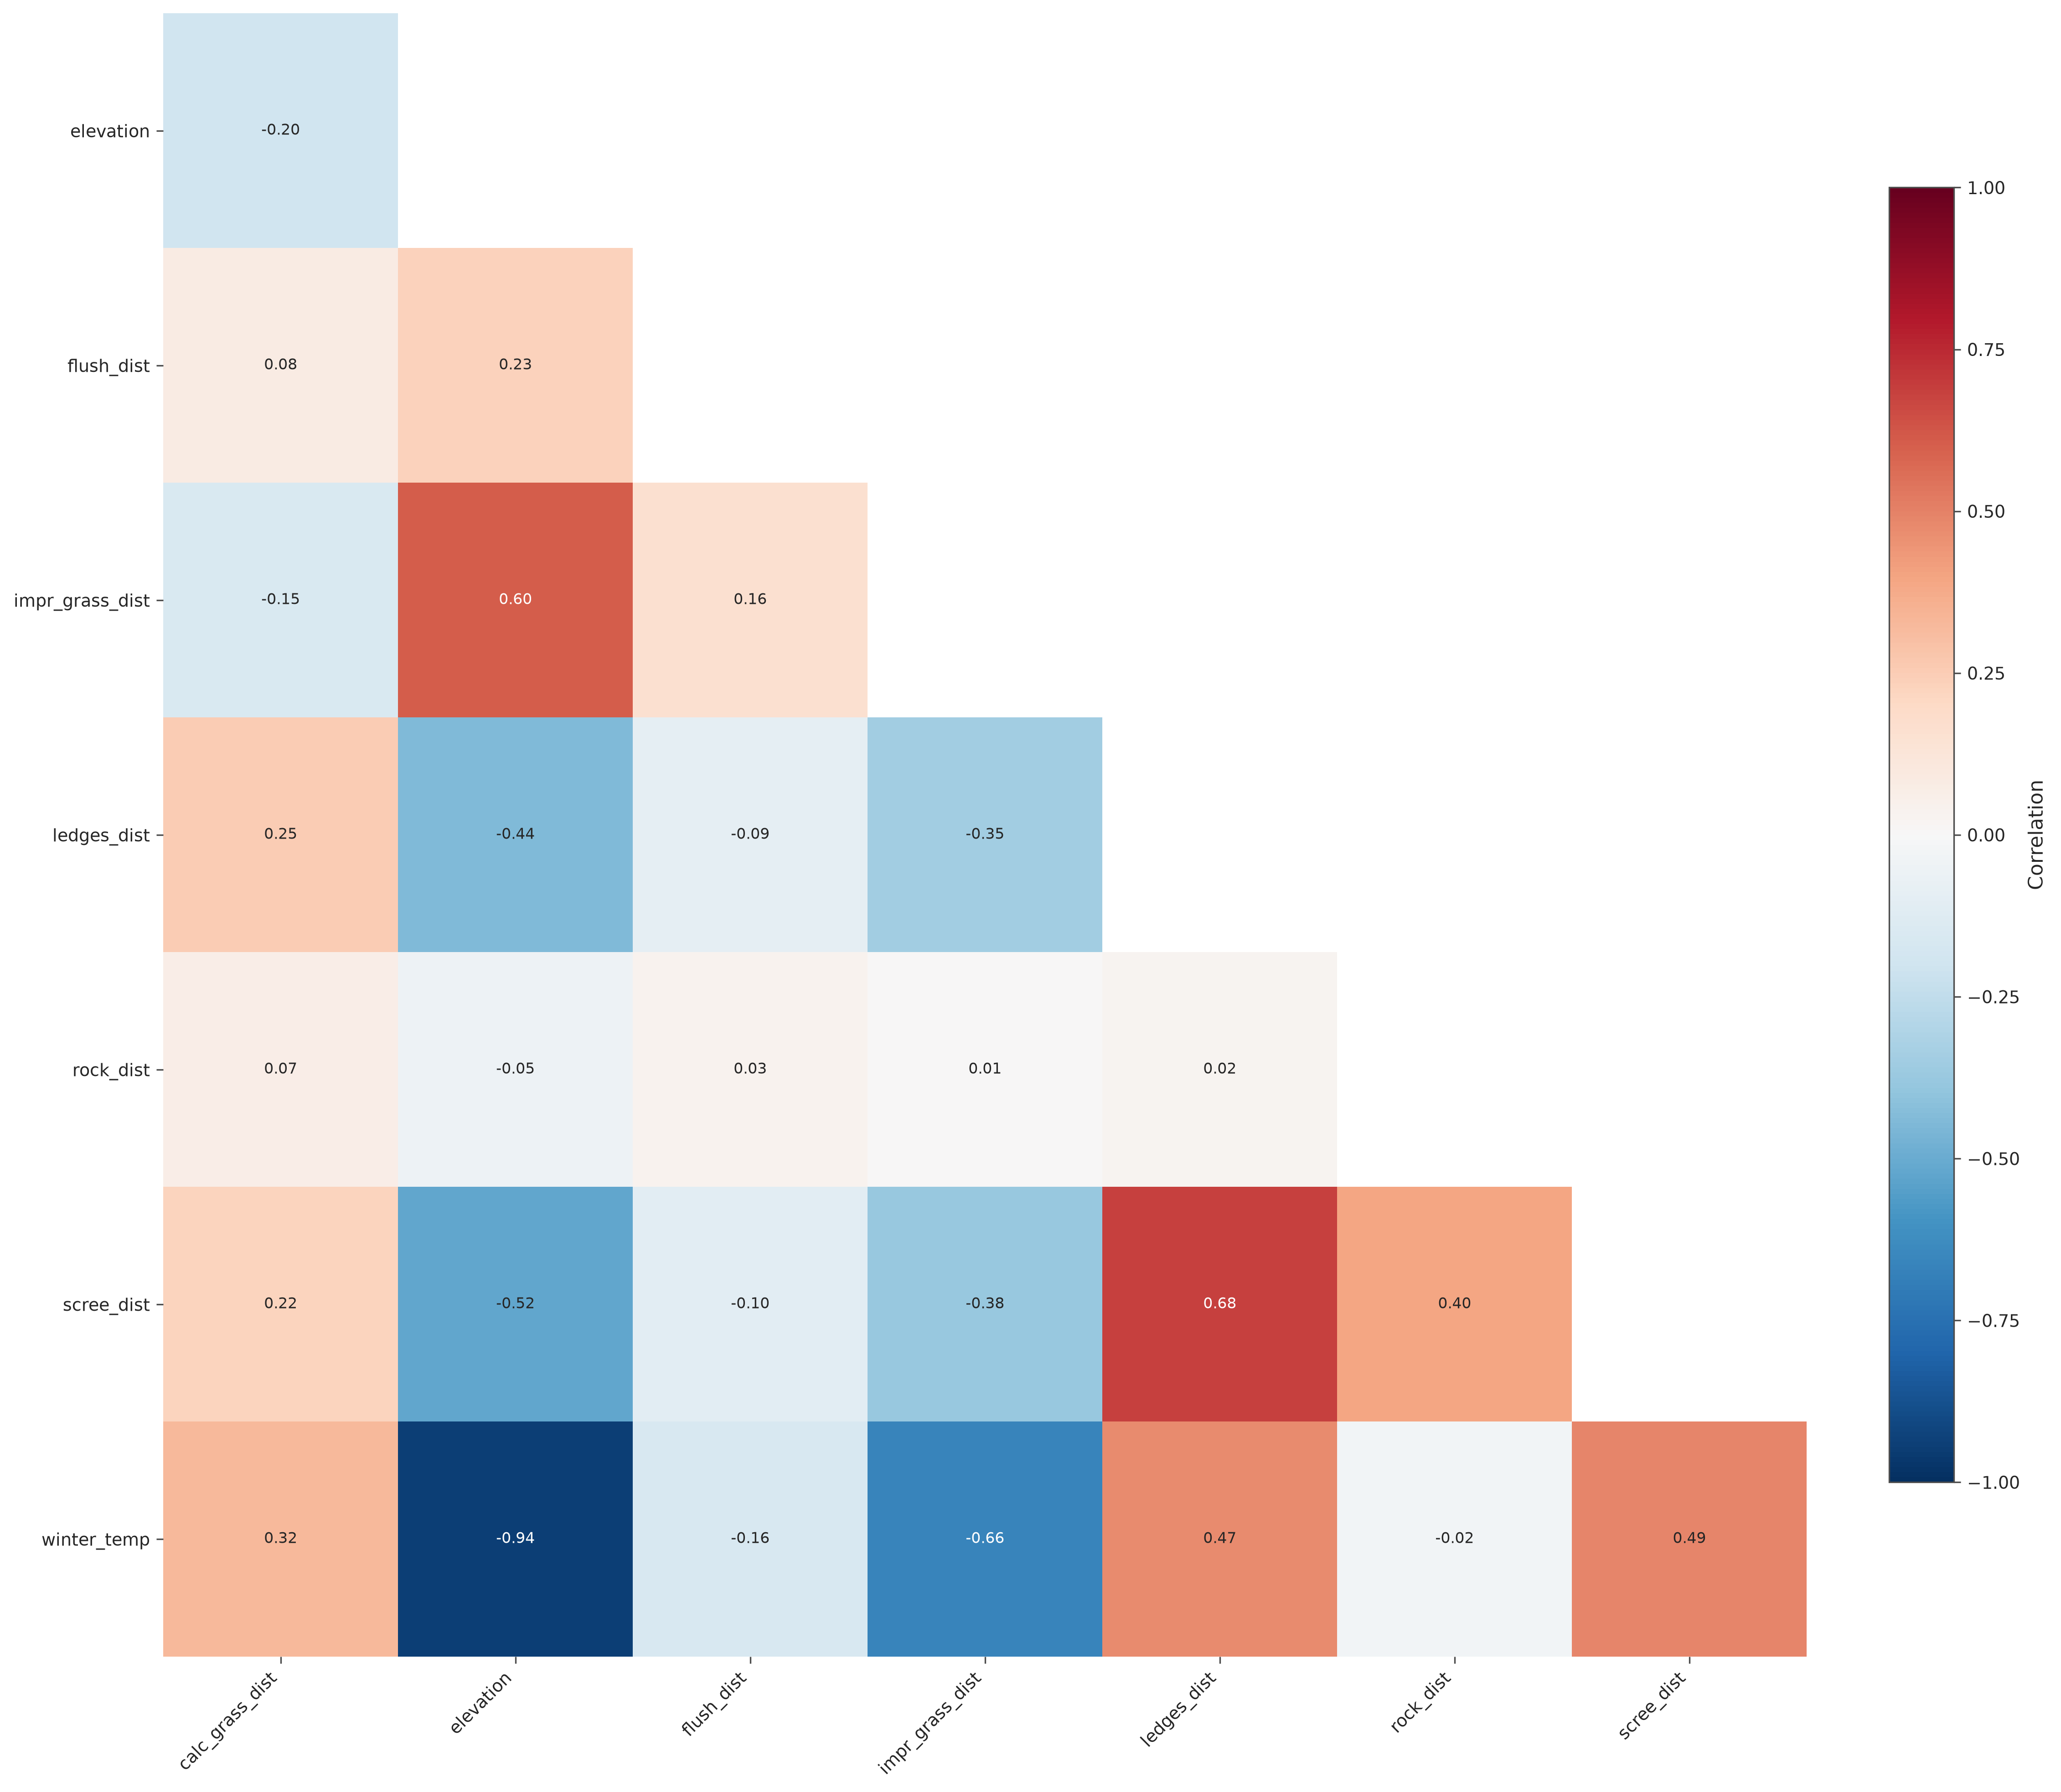

Calculating VIF for 8 predictors variables...


calc_grass_dist     1.3
elevation          12.4
flush_dist          1.1
impr_grass_dist     1.9
ledges_dist         2.2
rock_dist           1.5
scree_dist          3.0
winter_temp        14.5
Name: VIF, dtype: float64

In [8]:
corr_df = species_distribution.correlation_matrix(
    env_vars=env_vars,
    vec_file=samples_vec_file,
    vec_lyr=samples_vec_lyr,
    out_corr_file=os.path.join(out_dir, "correlation_matrix.csv"),
    out_plt_file=os.path.join(plots_dir, "correlation_matrix.png"),
)
display(Image(filename=os.path.join(plots_dir, "correlation_matrix.png"), width=700))
vif = species_distribution.calc_vif_multicollinearity(
    env_vars, samples_vec_file, samples_vec_lyr, out_vif_file=os.path.join(out_dir, "vif.csv")
)
vif.round(1)

Mean winter temperature and elevation are almost perfectly correlated (r = −0.94), and they are the only variables with a VIF above 10 (14.5 and 12.4). The distance to improved grassland is also correlated with both (r = −0.66 with temperature, 0.60 with elevation): improved grassland is in the warm valleys. The distances to scree and to ledges are related (r = 0.68: ledges are on crags, above scree), but below the thresholds.

We drop **elevation** and keep **winter temperature**. Temperature is the more direct (proximal) physiological factor for an insect and its food plant, and it is the variable a climate scenario changes. But be clear about what this means: *in this study area* the two are interchangeable, and the model cannot tell whether the beetle responds to temperature, or to something else that changes with altitude (less grazing on high crags, more rain, thinner soils, or simply where people have searched). The "temperature" response below is equally an elevation response, which matters when the model is used to project a warmer climate (section 16).

In [9]:
analysis_vars = [var_name for var_name in analysis_vars if var_name != "elevation"]
vif = species_distribution.calc_vif_multicollinearity(
    analysis_vars, samples_vec_file, samples_vec_lyr, out_vif_file=None
)
vif.round(2)

Calculating VIF for 7 predictors variables...


calc_grass_dist    1.17
flush_dist         1.06
impr_grass_dist    1.82
ledges_dist        2.22
rock_dist          1.45
scree_dist         2.87
winter_temp        2.29
Name: VIF, dtype: float64

Without elevation every VIF is below 3, so the remaining seven variables are acceptable for a regression.

## 6. Training and Test Sets

The samples are split into training (70 % of each class) and test (30 %) sets, separately for presences and pseudo-absences so both have the same class proportions. The split is saved, with the raw (un-standardised) values, so that notebooks 03 and 04 can fit MaxEnt and a random forest to exactly the same training data and evaluate them on the same test points.

In [10]:
train_vec_file = os.path.join(out_dir, "sdm_train.gpkg")
test_vec_file = os.path.join(out_dir, "sdm_test.gpkg")
species_distribution.create_train_test_sets(
    vec_file=samples_vec_file,
    vec_lyr=samples_vec_lyr,
    train_vec_file=train_vec_file,
    train_vec_lyr="train",
    test_vec_file=test_vec_file,
    test_vec_lyr="test",
    split_prop=0.7,
    cls_col="clsid",
    out_format="GPKG",
    rnd_seed=42,
)
train_gdf = geopandas.read_file(train_vec_file, layer="train")
test_gdf = geopandas.read_file(test_vec_file, layer="test")
print("Training:", train_gdf["clsid"].value_counts().to_dict())
print("Test:    ", test_gdf["clsid"].value_counts().to_dict())

Training: {0: 7000, 1: 23}
Test:     {0: 3000, 1: 11}


The training set has 23 presences and 7000 pseudo-absences, the test set 11 presences and 3000 pseudo-absences. **Eleven test presences is very few:** each one is 9 % of the sensitivity, and one presence more or less correctly ranked changes the test AUC by a few hundredths. Keep this uncertainty in mind for every test score below.

## 7. Standardise the Variables

Logistic regression is fitted with a penalty on the size of its coefficients (regularisation, section 8), so the variables must be on comparable scales, otherwise the penalty would act more strongly on some variables than others just because of their units (°C vs metres). `pop_normalise_coeffs` stores the mean and standard deviation of each variable, calculated from the **training** samples only, in its `EnvVarInfo` object; `apply_normalise_coeffs` converts the training and test tables to z-scores, and `normalise_data=True` applies the same conversion to the rasters when the model is used to make a map.

In [11]:
species_distribution.pop_normalise_coeffs(
    env_vars={name: env_vars[name] for name in analysis_vars},
    vec_file=train_vec_file,
    vec_lyr="train",
)
train_std_vec_file = os.path.join(out_dir, "sdm_train_std.gpkg")
test_std_vec_file = os.path.join(out_dir, "sdm_test_std.gpkg")
for in_file, in_lyr, out_file in [
    (train_vec_file, "train", train_std_vec_file),
    (test_vec_file, "test", test_std_vec_file),
]:
    species_distribution.apply_normalise_coeffs(
        env_vars={name: env_vars[name] for name in analysis_vars},
        vec_file=in_file,
        vec_lyr=in_lyr,
        out_vec_file=out_file,
        out_vec_lyr=in_lyr,
        out_format="GPKG",
    )
train_std_gdf = geopandas.read_file(train_std_vec_file, layer="train")
test_std_gdf = geopandas.read_file(test_std_vec_file, layer="test")
print(env_vars["winter_temp"])

winter_temp: ../data/sdm/environmental_data/Mean_Winter_Temp.tif (Band: 1) (Type: Continuous) (Range: None, None) (Normalisation: (x - 3.27714115548436) / 0.41496788201701823)


## 8. A Unimodal Temperature Response: a Logistic Regression Pipeline

A logistic regression models the log-odds of presence as a weighted sum of the variables, so with one term per variable every response is **monotonic**: suitability can only rise or only fall along each variable. That is reasonable for distances to a habitat, but not for temperature: a species' thermal niche is expected to be **unimodal**, with an optimum and limits on both sides. Here the beetle is absent from the warm valleys, but also (in recent decades) from the highest, coldest summits.

The usual solution is to add the square of the temperature as an extra term: the response in log-odds is then a parabola, which can have a peak. Because the temperatures are already standardised (mean 0), their square is centred on the mean of the training data, which keeps it nearly uncorrelated with the temperature itself.

Rather than making a temperature² raster, we build the squared term **inside** the model with a scikit-learn `Pipeline`: a `FunctionTransformer` adds the column `winter_temp_sq` to the table it is given, and the logistic regression is fitted to the result. The model's inputs are then still the seven variables, so every rsgispy function (cross-validation, response curves, jackknife, Sobol, the raster predictions) varies temperature and its square **together**, as it must; a separate temperature² variable would be varied independently of temperature, producing curves and sensitivity indices for impossible combinations. The function skips the term if temperature is not in the table, which the jackknife needs (it fits models without each variable).

`class_weight="balanced"` gives the presences and the pseudo-absences equal total weight, as recommended for many pseudo-absences (section 1).

In [12]:
def add_quadratic_temp(x_df):
    # Add the square of the (standardised) winter temperature, if present.
    if "winter_temp" in x_df.columns:
        x_df = x_df.assign(winter_temp_sq=x_df["winter_temp"] ** 2)
    return x_df


def make_lr_mdl(C=1.0, l1_ratio=0.0):
    return make_pipeline(
        FunctionTransformer(add_quadratic_temp),
        LogisticRegression(
            C=C,
            l1_ratio=l1_ratio,
            solver="liblinear",
            class_weight="balanced",
            max_iter=1000,
        ),
    )


vif_sq = species_distribution.calc_vif_multicollinearity(
    analysis_vars + ["winter_temp_sq"],
    add_quadratic_temp(train_std_gdf),
    None,
    out_vif_file=None,
)
vif_sq.round(2)

Calculating VIF for 8 predictors variables...


calc_grass_dist    1.23
flush_dist         1.14
impr_grass_dist    1.83
ledges_dist        2.23
rock_dist          1.53
scree_dist         2.89
winter_temp        2.51
winter_temp_sq     1.44
Name: VIF, dtype: float64

With the squared term added, all the VIFs are still below 3 (2.51 for temperature, 1.44 for its square): centring the temperature before squaring keeps the two terms nearly independent. Had we squared the raw temperatures (2.5–4.5 °C), the square would be almost perfectly correlated with the temperature itself.

## 9. Tune the Model with Spatial Cross-Validation

Logistic regression has one important hyperparameter: the strength of the regularisation, `C` (smaller `C` = stronger penalty on the coefficients). Ecologically, stronger regularisation means **smoother, simpler responses** that are less tied to the particular training sites, and so more likely to transfer to new places and times; weak regularisation lets the model fit every quirk of 24 training presences. `l1_ratio` chooses the type of penalty: 0 (L2, "ridge") shrinks all coefficients, 1 (L1, "lasso") can set some exactly to zero, i.e. removes variables.

Two things differ from the previous version of this tutorial:

* **Scoring by AUC, not accuracy.** With only about 0.3 % presences, a model that predicts "absent" everywhere is 99.7 % accurate. The ROC AUC (the probability that a random presence gets a higher score than a random pseudo-absence) does not depend on the class proportions.
* **Spatial blocks instead of random folds.** Most presences are within 2 km of each other (section 4). With random folds, almost every held-out presence has a training presence a few metres away with nearly the same values, so the cross-validation rewards models that memorise the sites. `SpatialBlockKFold` assigns whole 1 km × 1 km blocks to folds, so each fold is scored on places the model has not seen.

Choosing the blocks is a compromise. Ideally they would be larger than the range of the autocorrelation (2–4 km, section 4), but the 23 training presences fall in only ten 1 km blocks, one of which holds ten of them: with 2 km blocks nearly all the presences would be in one block, and a fold without presences cannot be scored. We use 1 km blocks and **3 folds**, and check that every held-out fold has presences. (With 5 folds, `stratify=True` still left one fold without presences here: it balances the *counts* of each class between folds, which with 7000 pseudo-absences and 23 presences is dominated by the pseudo-absences.) Because the blocks are smaller than the autocorrelation range, the spatial scores below are still somewhat optimistic.

(The previous version also "tuned" `max_iter` and `tol`, which are settings of the solver, not of the model.)

In [13]:
train_xy = numpy.column_stack([train_std_gdf.geometry.x, train_std_gdf.geometry.y])
blk_cv = SpatialBlockKFold(n_splits=3, block_size=1000.0, stratify=True, rnd_seed=42)
blk_splits = list(
    blk_cv.split(train_std_gdf[analysis_vars], train_std_gdf["clsid"], coords=train_xy)
)
print("Presences in each held-out fold:",
      [int(train_std_gdf["clsid"].iloc[test_idx].sum()) for _, test_idx in blk_splits])

grid_space = {
    "logisticregression__C": [0.001, 0.01, 0.1, 1.0, 10.0],
    "logisticregression__l1_ratio": [0.0, 1.0],
}
search_obj = GridSearchCV(make_lr_mdl(), param_grid=grid_space, cv=blk_splits, scoring="roc_auc")
opt_mdl, opt_mdl_params = species_distribution.search_mdl_params(
    search_obj=search_obj,
    train_vec_file=train_std_gdf,
    train_vec_lyr=None,
    analysis_vars=analysis_vars,
    cls_col="clsid",
)
print("Highest spatial CV AUC:", opt_mdl_params)

# search_mdl_params fits a copy of the search object; fit it again here
# to see the cross-validated AUC of every combination.
search_obj.fit(train_std_gdf[analysis_vars], train_std_gdf["clsid"])
cv_res_df = pandas.DataFrame(search_obj.cv_results_)[
    ["param_logisticregression__C", "param_logisticregression__l1_ratio", "mean_test_score", "std_test_score"]
]
cv_res_df.columns = ["C", "l1_ratio", "auc_mean", "auc_sd"]
cv_res_df["auc_se"] = cv_res_df["auc_sd"] / numpy.sqrt(len(blk_splits))
cv_res_df.round(3)

Presences in each held-out fold: [5, 7, 11]


Best score was 0.9419942188134559 and has parameters {'logisticregression__C': 10.0, 'logisticregression__l1_ratio': 0.0}.
Highest spatial CV AUC: {'logisticregression__C': 10.0, 'logisticregression__l1_ratio': 0.0}


,C,l1_ratio,auc_mean,auc_sd,auc_se
0,0.001,0.0,0.914,0.041,0.024
1,0.001,1.0,0.888,0.020,0.012
2,0.010,0.0,0.925,0.033,0.019
3,0.010,1.0,0.925,0.027,0.015
4,0.100,0.0,0.935,0.024,0.014
5,0.100,1.0,0.941,0.021,0.012
6,1.000,0.0,0.941,0.022,0.013
7,1.000,1.0,0.941,0.022,0.013
8,10.000,0.0,0.942,0.022,0.013
9,10.000,1.0,0.940,0.023,0.014


Every held-out fold has presences (5, 7 and 11). The spatial cross-validated AUC rises from 0.89–0.91 with the strongest regularisation (`C` = 0.001) to about 0.94 at `C` = 0.1, and is then flat: weaker regularisation (larger `C`) gains nothing. The highest mean AUC (0.942, with `C` = 10 and an L2 penalty) is no better than several more strongly regularised settings, given a standard error of about 0.013.

**Choosing the regularisation: the one-standard-error rule.** When several settings score almost the same, the differences between them are mostly noise (there are only 23 training presences, in three folds). A standard rule is to choose the **simplest** (most strongly regularised) model whose score is within one standard error of the best. This guards against choosing a weakly regularised model that fits the training sites closely and transfers poorly, which matters for an SDM that may be projected to other conditions. Between equally regularised settings we take the higher AUC.

In [14]:
best_row = cv_res_df.loc[cv_res_df["auc_mean"].idxmax()]
ok_df = cv_res_df[cv_res_df["auc_mean"] >= best_row["auc_mean"] - best_row["auc_se"]]
sel_row = ok_df.sort_values(["C", "auc_mean"], ascending=[True, False]).iloc[0]
mdl_params = {"C": float(sel_row["C"]), "l1_ratio": float(sel_row["l1_ratio"])}
rsgispy.tools.jsonio.write_dict_to_json(mdl_params, os.path.join(out_dir, "lr_mdl_params.json"))
print(f"Best AUC {best_row['auc_mean']:.3f} (SE {best_row['auc_se']:.3f}); "
      f"selected {mdl_params} with AUC {sel_row['auc_mean']:.3f}")

Best AUC 0.942 (SE 0.013); selected {'C': 0.1, 'l1_ratio': 1.0} with AUC 0.941


## 10. Fit a Single Model and Evaluate It

`fit_sklearn_mdl` fits the model to the training set (`return_model=True` returns the fitted model). We evaluate it on the test set with `calc_sdm_eval_metrics`, which returns the usual SDM measures:

* **AUC** — threshold-independent ranking: 0.5 is random, 1 perfect. With pseudo-absences the maximum achievable AUC is below 1, because some pseudo-absences fall in suitable habitat.
* **TSS** (true skill statistic = sensitivity + specificity − 1) at the threshold that maximises it, with the **sensitivity** (proportion of presences predicted present) and **specificity** (proportion of pseudo-absences predicted absent) at that threshold.
* **Boyce index** (`bg_scores="absences"`) — the standard measure for presence-only data. It compares, along the range of predicted values, the share of presences with the share of background points (the "predicted/expected" ratio). For a good model the ratio rises steadily with the prediction, and the index (a rank correlation of the ratio with the prediction) is close to 1; 0 is random. It needs no true absences, so it is not penalised when pseudo-absences fall in suitable habitat.

We do not report accuracy (see section 9).

In [15]:
lr_mdl, train_acc, test_acc, test_auc = species_distribution.fit_sklearn_mdl(
    est_cls_obj=make_lr_mdl(**mdl_params),
    train_vec_file=train_std_gdf,
    train_vec_lyr=None,
    test_vec_file=test_std_gdf,
    test_vec_lyr=None,
    analysis_vars=analysis_vars,
    cls_col="clsid",
    return_model=True,
)
lr_coefs = pandas.Series(
    lr_mdl[-1].coef_[0], index=lr_mdl[-1].feature_names_in_, name="coefficient"
)
print(lr_coefs.round(3))

test_y = test_std_gdf["clsid"].to_numpy()
test_probs = species_distribution.get_positive_class_probs(lr_mdl, test_std_gdf[analysis_vars])
lr_metrics = species_distribution.calc_sdm_eval_metrics(test_y, test_probs, bg_scores="absences")
pandas.Series(lr_metrics).round(3)

Classifier Train Score = 87.18%
Classifier Test Score = 86.82%
calc_grass_dist   -0.042
flush_dist         0.945
impr_grass_dist    0.130
ledges_dist       -4.227
rock_dist         -0.443
scree_dist         1.826
winter_temp       -6.218
winter_temp_sq    -2.676
Name: coefficient, dtype: float64


auc                     0.964
threshold               0.619
tss                     0.897
sensitivity             1.000
specificity             0.897
omission_rate           0.000
commission_rate         0.103
kappa                   0.060
accuracy                0.897
balanced_accuracy       0.948
prevalence              0.004
n_presence             11.000
n_absence            3000.000
boyce                   0.940
dtype: float64

The model (`C` = 0.1, L1 penalty) ranks the test points well: AUC 0.964. At the threshold that maximises TSS (0.619) all 11 test presences are predicted present (sensitivity 1.0) and 89.7 % of the test pseudo-absences absent (specificity 0.897), giving TSS = 0.897. The Boyce index of 0.94 shows that the share of presences rises steadily with the predicted suitability, as it should for a good presence-only model.

Notice how misleading the threshold-dependent measures that depend on prevalence are: kappa is only 0.06, because with 11 presences among 3011 points even a 10 % false positive rate means about 300 pseudo-absences predicted present; and the "accuracy" (0.897) is lower than that of a model predicting "absent" everywhere (0.996). This is why we report AUC, TSS and the Boyce index.

The coefficients (for standardised variables, on the log-odds scale) are largest for winter temperature (−6.2, and −2.7 for its square: a peak at the cold end of the range) and the distance to ledges (−4.2: suitability falls away from ledges). They are discussed with the response curves in section 13.

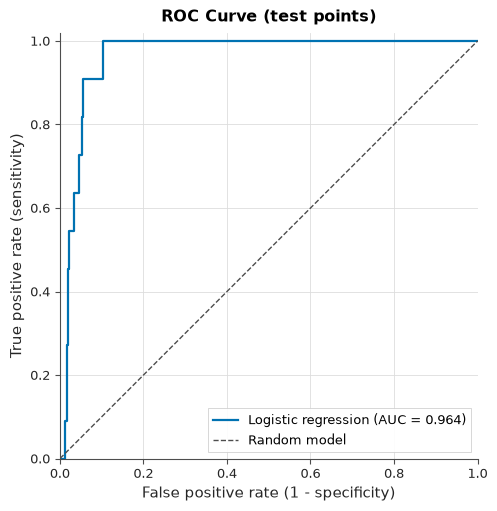

In [16]:
fpr, tpr, auc = species_distribution.calc_binary_roc_auc(test_y, test_probs)
fig, ax = species_distribution.plot_roc_curve(
    fpr, tpr, auc, label="Logistic regression", title="ROC Curve (test points)",
    out_plot_file=os.path.join(plots_dir, "lr_testing_roc_curve.png"),
)

**Is the AUC better than chance?** With few presences, a model can reach a high AUC even when there is no real signal. `calc_null_model_auc` tests this (Raes & ter Steege 2007): 99 times, it labels the same number of **random** background points as "presences", fits the model to them, and calculates the AUC on the test set in the same way. The null AUCs show what AUC this model reaches by chance in this study area; the observed AUC should be well above their 95th percentile.

In [17]:
null_res = species_distribution.calc_null_model_auc(
    make_lr_mdl(**mdl_params),
    train_std_gdf,
    None,
    test_std_gdf,
    None,
    analysis_vars,
    n_pres=int(train_std_gdf["clsid"].sum()),
    n_reps=99,
    observed_auc=lr_metrics["auc"],
    rnd_seed=42,
    plot_file=os.path.join(plots_dir, "null_model_auc.png"),
    use_pbar=False,
)
print(f"Null AUC: mean {null_res['null_mean']:.3f}, 95th percentile {null_res['null_p95']:.3f}")
print(f"Observed AUC {null_res['observed_auc']:.3f}, p = {null_res['p_value']:.3f}")

# Save the scores for the comparison in notebook 05.
lr_metrics["null_p95"] = null_res["null_p95"]
lr_metrics["null_p_value"] = null_res["p_value"]
rsgispy.tools.jsonio.write_dict_to_json(
    {key: float(val) for key, val in lr_metrics.items()},
    os.path.join(out_dir, "lr_test_metrics.json"),
)

Null AUC: mean 0.513, 95th percentile 0.676
Observed AUC 0.964, p = 0.010


The 99 null models, fitted to random "presences", reach a mean test AUC of 0.513 and a 95th percentile of 0.676. The observed AUC (0.964) is far above all of them (p = 0.01, the smallest p-value possible with 99 replicates), so the model has found a real signal, not a chance pattern. With 23 training presences, null AUCs up to about 0.68 are possible: an AUC of 0.7 on its own would not have been convincing.

## 11. An Ensemble with Spatial Cross-Validation

A single model depends on which samples it was trained on. An ensemble of models, each fitted to a different part of the training data, gives a more stable prediction (the median of its members) and shows how much the result depends on the data. With `cv`, `fit_kfold_sklearn_mdls` fits one member per fold of the splitter and scores it on that fold's held-out rows (`val_*` columns: out-of-fold AUC, TSS and Boyce index), as well as on the common test set (`test_*`).

We fit two ensembles of three members, one with random folds and one with the 1 km spatial blocks of section 9, to see how much random cross-validation flatters the model. The spatial ensemble is used for the maps.

In [18]:
rnd_mdls, rnd_scores_df = species_distribution.fit_kfold_sklearn_mdls(
    make_lr_mdl(**mdl_params),
    train_std_gdf, None, test_std_gdf, None, analysis_vars,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    rnd_seed=42, return_scores=True, use_pbar=False,
)
lr_mdls, lr_scores_df = species_distribution.fit_kfold_sklearn_mdls(
    make_lr_mdl(**mdl_params),
    train_std_gdf, None, test_std_gdf, None, analysis_vars,
    cv=blk_cv,
    rnd_seed=42, return_scores=True, use_pbar=False,
)
lr_scores_df.to_csv(os.path.join(out_dir, "lr_spatial_cv_scores.csv"), index=False)
score_cols = ["val_auc", "val_tss", "val_boyce", "test_auc", "test_tss"]
cv_cmp_df = pandas.DataFrame(
    {
        "random CV (mean)": rnd_scores_df[score_cols].mean(),
        "spatial CV (mean)": lr_scores_df[score_cols].mean(),
        "spatial CV (sd)": lr_scores_df[score_cols].std(),
    }
)
print(lr_scores_df[["fold", "n_train", "n_val"] + score_cols].round(3))
cv_cmp_df.round(3)

ROC: 0.957939393939394 - 0.9635757575757575 - 0.9638484848484848
Train: 0.8611704399829133 - 0.8680051260145237 - 0.884878257155062
Test: 0.8551976087678512 - 0.858850880106277 - 0.8840916638990368
Validation (out-of-fold) ROC: 0.9428311187312473 - 0.9446688701187416 - 0.9587976853836262


ROC: 0.953060606060606 - 0.9564545454545453 - 0.9655151515151514
Train: 0.8490808037622916 - 0.8834578441835645 - 0.8842622250694
Test: 0.8432414480239123 - 0.8548654931916306 - 0.9026901361673862
Validation (out-of-fold) ROC: 0.9141020145735106 - 0.9432367889290307 - 0.9647113811638233
   fold  n_train   n_val  val_auc  val_tss  val_boyce  test_auc  test_tss
0     0   4685.0  2338.0    0.914    0.880      0.282     0.956     0.886
1     1   4683.0  2340.0    0.943    0.836      0.734     0.966     0.936
2     2   4678.0  2345.0    0.965    0.873      0.902     0.953     0.864


,random CV (mean),spatial CV (mean),spatial CV (sd)
val_auc,0.949,0.941,0.025
val_tss,0.855,0.863,0.023
val_boyce,0.638,0.639,0.321
test_auc,0.962,0.958,0.006
test_tss,0.906,0.896,0.037


The three spatial members have out-of-fold AUCs of 0.914, 0.943 and 0.965 (mean 0.941), and TSS between 0.84 and 0.88. The random folds give a slightly higher mean out-of-fold AUC (0.949): a gap of only 0.008, much smaller than the 0.04 of the random forest in the rsgispy guide. A heavily regularised logistic regression produces smooth responses and cannot "memorise" individual sites the way a random forest can, so it gains little from having nearby training points. (The 1 km blocks are smaller than the range of the autocorrelation, so the spatial scores are still somewhat optimistic.)

The out-of-fold Boyce index varies a lot between folds (0.28, 0.73 and 0.90): with only 5–11 presences in a fold, the Boyce index (which bins the presences along the predicted values) is very unstable, so its mean (0.64) should be read as "positive, but poorly estimated". Report the spatial cross-validation scores (AUC 0.94 ± 0.03, TSS 0.86) as the accuracy of the model.

On the common test set, the median of the three members has AUC 0.964, TSS 0.908 and Boyce index 0.889, similar to the single model.

In [19]:
# Ensemble prediction for the test points: the median of the members.
ens_test_probs = numpy.median(
    [species_distribution.get_positive_class_probs(mdl, test_std_gdf[analysis_vars]) for mdl in lr_mdls],
    axis=0,
)
lr_ens_metrics = species_distribution.calc_sdm_eval_metrics(test_y, ens_test_probs, bg_scores="absences")
# Save the test scores so notebook 05 can compare the models on the same points.
pandas.DataFrame({"clsid": test_y, "ens_prob": ens_test_probs}).to_csv(
    os.path.join(out_dir, "lr_test_scores.csv"), index=False
)
pandas.Series(lr_ens_metrics).round(3)

auc                     0.964
threshold               0.663
tss                     0.908
sensitivity             1.000
specificity             0.908
omission_rate           0.000
commission_rate         0.092
kappa                   0.068
accuracy                0.909
balanced_accuracy       0.954
prevalence              0.004
n_presence             11.000
n_absence            3000.000
boyce                   0.889
dtype: float64

## 12. Residual Spatial Autocorrelation

If the model has captured the reasons why the beetle is where it is, what is left over (the residuals, class − predicted probability) should not be spatially structured. `calc_residual_autocorrelation` calculates a Moran's I correlogram of the residuals of the training samples. Significantly positive Moran's I at short distances means nearby samples share something the model has not explained: a missing variable, clusters of records, or survey bias; the samples are then not independent, and only spatially cross-validated scores should be reported.

In [20]:
resid_df = species_distribution.calc_residual_autocorrelation(
    lr_mdl,
    train_std_gdf,
    None,
    analysis_vars,
    dist_classes=dist_classes,
    n_perms=99,
    rnd_seed=42,
    plot_file=os.path.join(plots_dir, "residual_correlogram.png"),
)
resid_df[["dist_lower", "dist_upper", "n_pairs", "morans_i", "p_value"]].round(3)

,dist_lower,dist_upper,n_pairs,morans_i,p_value
0,0.0,250.0,55998.0,0.923,0.01
1,250.0,500.0,165738.0,0.816,0.01
2,500.0,1000.0,634482.0,0.631,0.01
3,1000.0,1500.0,1010924.0,0.442,0.01
4,1500.0,2000.0,1346062.0,0.314,0.01
5,2000.0,3000.0,3515040.0,0.157,0.01
6,3000.0,4000.0,4344658.0,0.014,0.01
7,4000.0,6000.0,10032434.0,-0.063,0.01


The residuals are strongly autocorrelated: Moran's I is 0.92 between training samples less than 250 m apart and falls to about 0 only at 3–4 km, the same range as the covariates themselves (section 4).

Part of this is built into presence–background models: 99.7 % of the samples are pseudo-absences, whose residual is simply minus their predicted suitability, and that prediction varies smoothly in space because the covariates do. But it also means that nearby samples share unexplained variation (missing variables, the clustering of the records), so the samples are not independent. This is the reason to rely on the spatial cross-validation scores, and a warning against over-interpreting small differences in the test scores.

## 13. Interpreting the Model: What Has It Learnt About the Beetle's Niche?

A model that predicts well can still be ecologically implausible, for example if it relies on survey bias or a correlated stand-in for the real driver. Four complementary tools show what the model has learnt. Each answers a different question:

| Tool | Question |
| --- | --- |
| Response curves | How does suitability change along each variable? |
| Jackknife | Which variables carry information, and which can be removed? |
| SHAP | How much does each variable push each prediction up or down? |
| Sobol indices | Which variables drive the variation of the predictions over their ranges, alone and in interaction? |

### 13.1 Response Curves

`sklearn_mdl_variable_response_curves` varies one variable over the range of the training data while holding the others at their mean value at the presences, and records the predicted suitability. With `normalised_data=True` and `env_vars`, the values are converted back to the original units (°C and metres). The returned table has `<var>_vals` and `<var>_resp` columns; we plot all the curves together, with the values at the training presences as ticks along the bottom of each plot.

calc_grass_dist Range:	(-1.3740436508556557 - 3.630011875222729): Mean = -0.323876026760421
Calculating Response Curve for 'calc_grass_dist'
flush_dist Range:	(-1.346681105295006 - 4.714882643026467): Mean = 1.1973900209751838
Calculating Response Curve for 'flush_dist'
impr_grass_dist Range:	(-1.51565710620492 - 2.995774730255979): Mean = 0.8368067417629487
Calculating Response Curve for 'impr_grass_dist'
ledges_dist Range:	(-1.567734096828793 - 2.818119209626168): Mean = -1.2754614148047803
Calculating Response Curve for 'ledges_dist'
rock_dist Range:	(-1.526694759159994 - 3.43574410486953): Mean = 0.2209963058113201
Calculating Response Curve for 'rock_dist'
scree_dist Range:	(-1.2370179964047996 - 3.2003488915161715): Mean = -0.6104260877632824
Calculating Response Curve for 'scree_dist'
winter_temp Range:	(-1.8555286247008138 - 2.804297434072814): Mean = -1.0202122315641022
Calculating Response Curve for 'winter_temp'


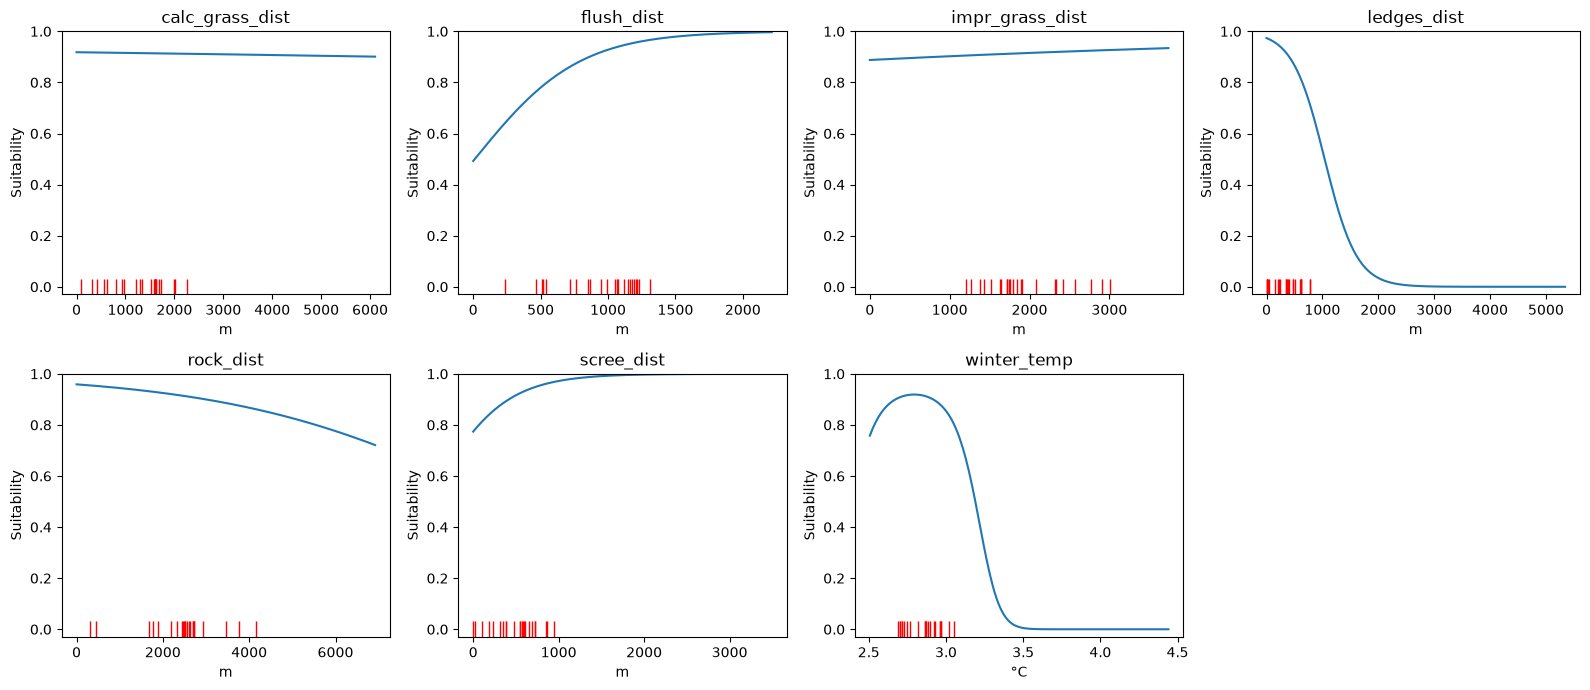

In [21]:
resp_df = species_distribution.sklearn_mdl_variable_response_curves(
    est_cls_obj=lr_mdl,
    train_vec_file=train_std_gdf,
    train_vec_lyr=None,
    analysis_vars=analysis_vars,
    output_file=os.path.join(out_dir, "lr_response_curves.csv"),
    response_plots_dir=None,
    n_samples=200,
    cls_col="clsid",
    normalised_data=True,
    env_vars=env_vars,
)
train_pres_gdf = train_gdf[train_gdf["clsid"] == 1]
units = {"winter_temp": "°C"}
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, var_name in zip(axs.flatten(), analysis_vars):
    ax.plot(resp_df[f"{var_name}_vals"], resp_df[f"{var_name}_resp"], color="tab:blue")
    ax.plot(train_pres_gdf[var_name], numpy.zeros(len(train_pres_gdf)), "|", color="red", ms=12)
    ax.set_ylim(-0.03, 1.0)
    ax.set_title(var_name)
    ax.set_xlabel(units.get(var_name, "m"))
    ax.set_ylabel("Suitability")
axs.flatten()[-1].axis("off")
fig.tight_layout()

In [22]:
# Where along each variable does suitability fall to half of its maximum?
half_rows = []
for var_name in analysis_vars:
    vals = resp_df[f"{var_name}_vals"].to_numpy()
    resp = resp_df[f"{var_name}_resp"].to_numpy()
    above = vals[resp >= resp.max() / 2]
    half_rows.append(
        {
            "variable": var_name,
            "max suitability": resp.max(),
            "at value": vals[resp.argmax()],
            "suitability >= half max from": above.min(),
            "to": above.max(),
            "training range": f"{vals.min():.1f} – {vals.max():.1f}",
        }
    )
pandas.DataFrame(half_rows).round(2)

,variable,max suitability,at value,suitability >= half max from,to,training range
0,calc_grass_dist,0.92,0.00,0.00,6102.75,0.0 – 6102.8
1,flush_dist,1.00,2214.50,11.13,2214.50,0.0 – 2214.5
2,impr_grass_dist,0.93,3739.73,0.00,3739.73,0.0 – 3739.7
3,ledges_dist,0.97,0.00,0.00,1046.91,0.0 – 5341.9
4,rock_dist,0.96,0.00,0.00,6917.60,0.0 – 6917.6
5,scree_dist,1.00,3493.14,0.00,3493.14,0.0 – 3493.1
6,winter_temp,0.92,2.80,2.51,3.20,2.5 – 4.4


The responses, one variable at a time with the others at their mean at the presences:

* **Distance to species-rich ledges** — the dominant habitat response: suitability is above 0.9 within about 500 m of a ledge, falls to half its maximum at about 1050 m, and is close to 0 beyond 2 km. All the training presences are within about 800 m of a mapped ledge. Given the positional errors of the records and the ledge patches hidden in mosaics (notebook 01), this is consistent with a beetle that lives on, or very close to, the thyme of the ledges.
* **Winter temperature** — unimodal, as allowed by the quadratic term: suitability peaks at about 2.8 °C and is above half its maximum between the coldest values in the study area (2.5 °C) and about 3.2 °C, then falls steeply to 0 above about 3.4 °C. In this study area winter temperature falls by about 0.2 °C per 100 m of altitude (section 16), so the optimum corresponds to roughly 700 m and the warm limit to roughly 500 m, remarkably close to the 738 m mean and 555 m lowest record of the NRW surveys. The decline at the cold end is mild (0.92 at the optimum, 0.76 at 2.5 °C): the data say little about an upper altitude limit, as there is very little land colder than the coldest presences.
* **Distance to flushes** — suitability *rises* away from flushes (0.49 at a flush, almost 1 beyond 1.5 km): the beetle's sites are on dry ground (section 3).
* **Distance to improved grassland** — a slight rise (0.89 to 0.93): avoidance of improved pasture, weak once temperature is accounted for, since improved grassland is in the warm valleys anyway.
* **Distance to rock exposures** — a slight fall (0.96 to 0.72 over 7 km), in the direction hypothesised in notebook 01, although the raw data showed presences *further* from rock than the study area (section 3): with the other variables held constant, the sign of a weak effect can reverse.
* **Distance to scree** — suitability *rises* away from scree (0.77 to 1.0). This is **ecologically implausible** (scree and its margins are good thyme habitat, and the presences are, if anything, slightly closer to scree than the study area). It is a typical collinearity artefact: scree and ledges are correlated (r = 0.68), and once the strong ledge effect is in the model, the scree coefficient adjusts the fit for places that are near scree but not near ledges. It should not be read as avoidance of scree.
* **Distance to calcareous grassland** — flat: no effect (its coefficient is almost exactly zero).

Two limits of these curves: they hold the other variables at their mean at the presences, where suitability is already high (hence maxima of 0.9–1.0), and they show one variable at a time, so they cannot show interactions. The predicted values are relative suitabilities: with `class_weight="balanced"` they are scaled as if presences and pseudo-absences were equally common.

### 13.2 Jackknife Variable Importance

`sklearn_jackknife_var_importance` refits the model leaving each variable out (`*_leave_var_out` columns), and with each variable alone (`*_only_var`), and reports the test AUC (`roc_test_acc_*`) and accuracies of each. A variable with a high AUC **on its own** carries a lot of information about where the beetle is; a variable whose **removal** lowers the AUC most carries information that no other variable has. An untrained model is passed, because it is cloned and refitted many times.

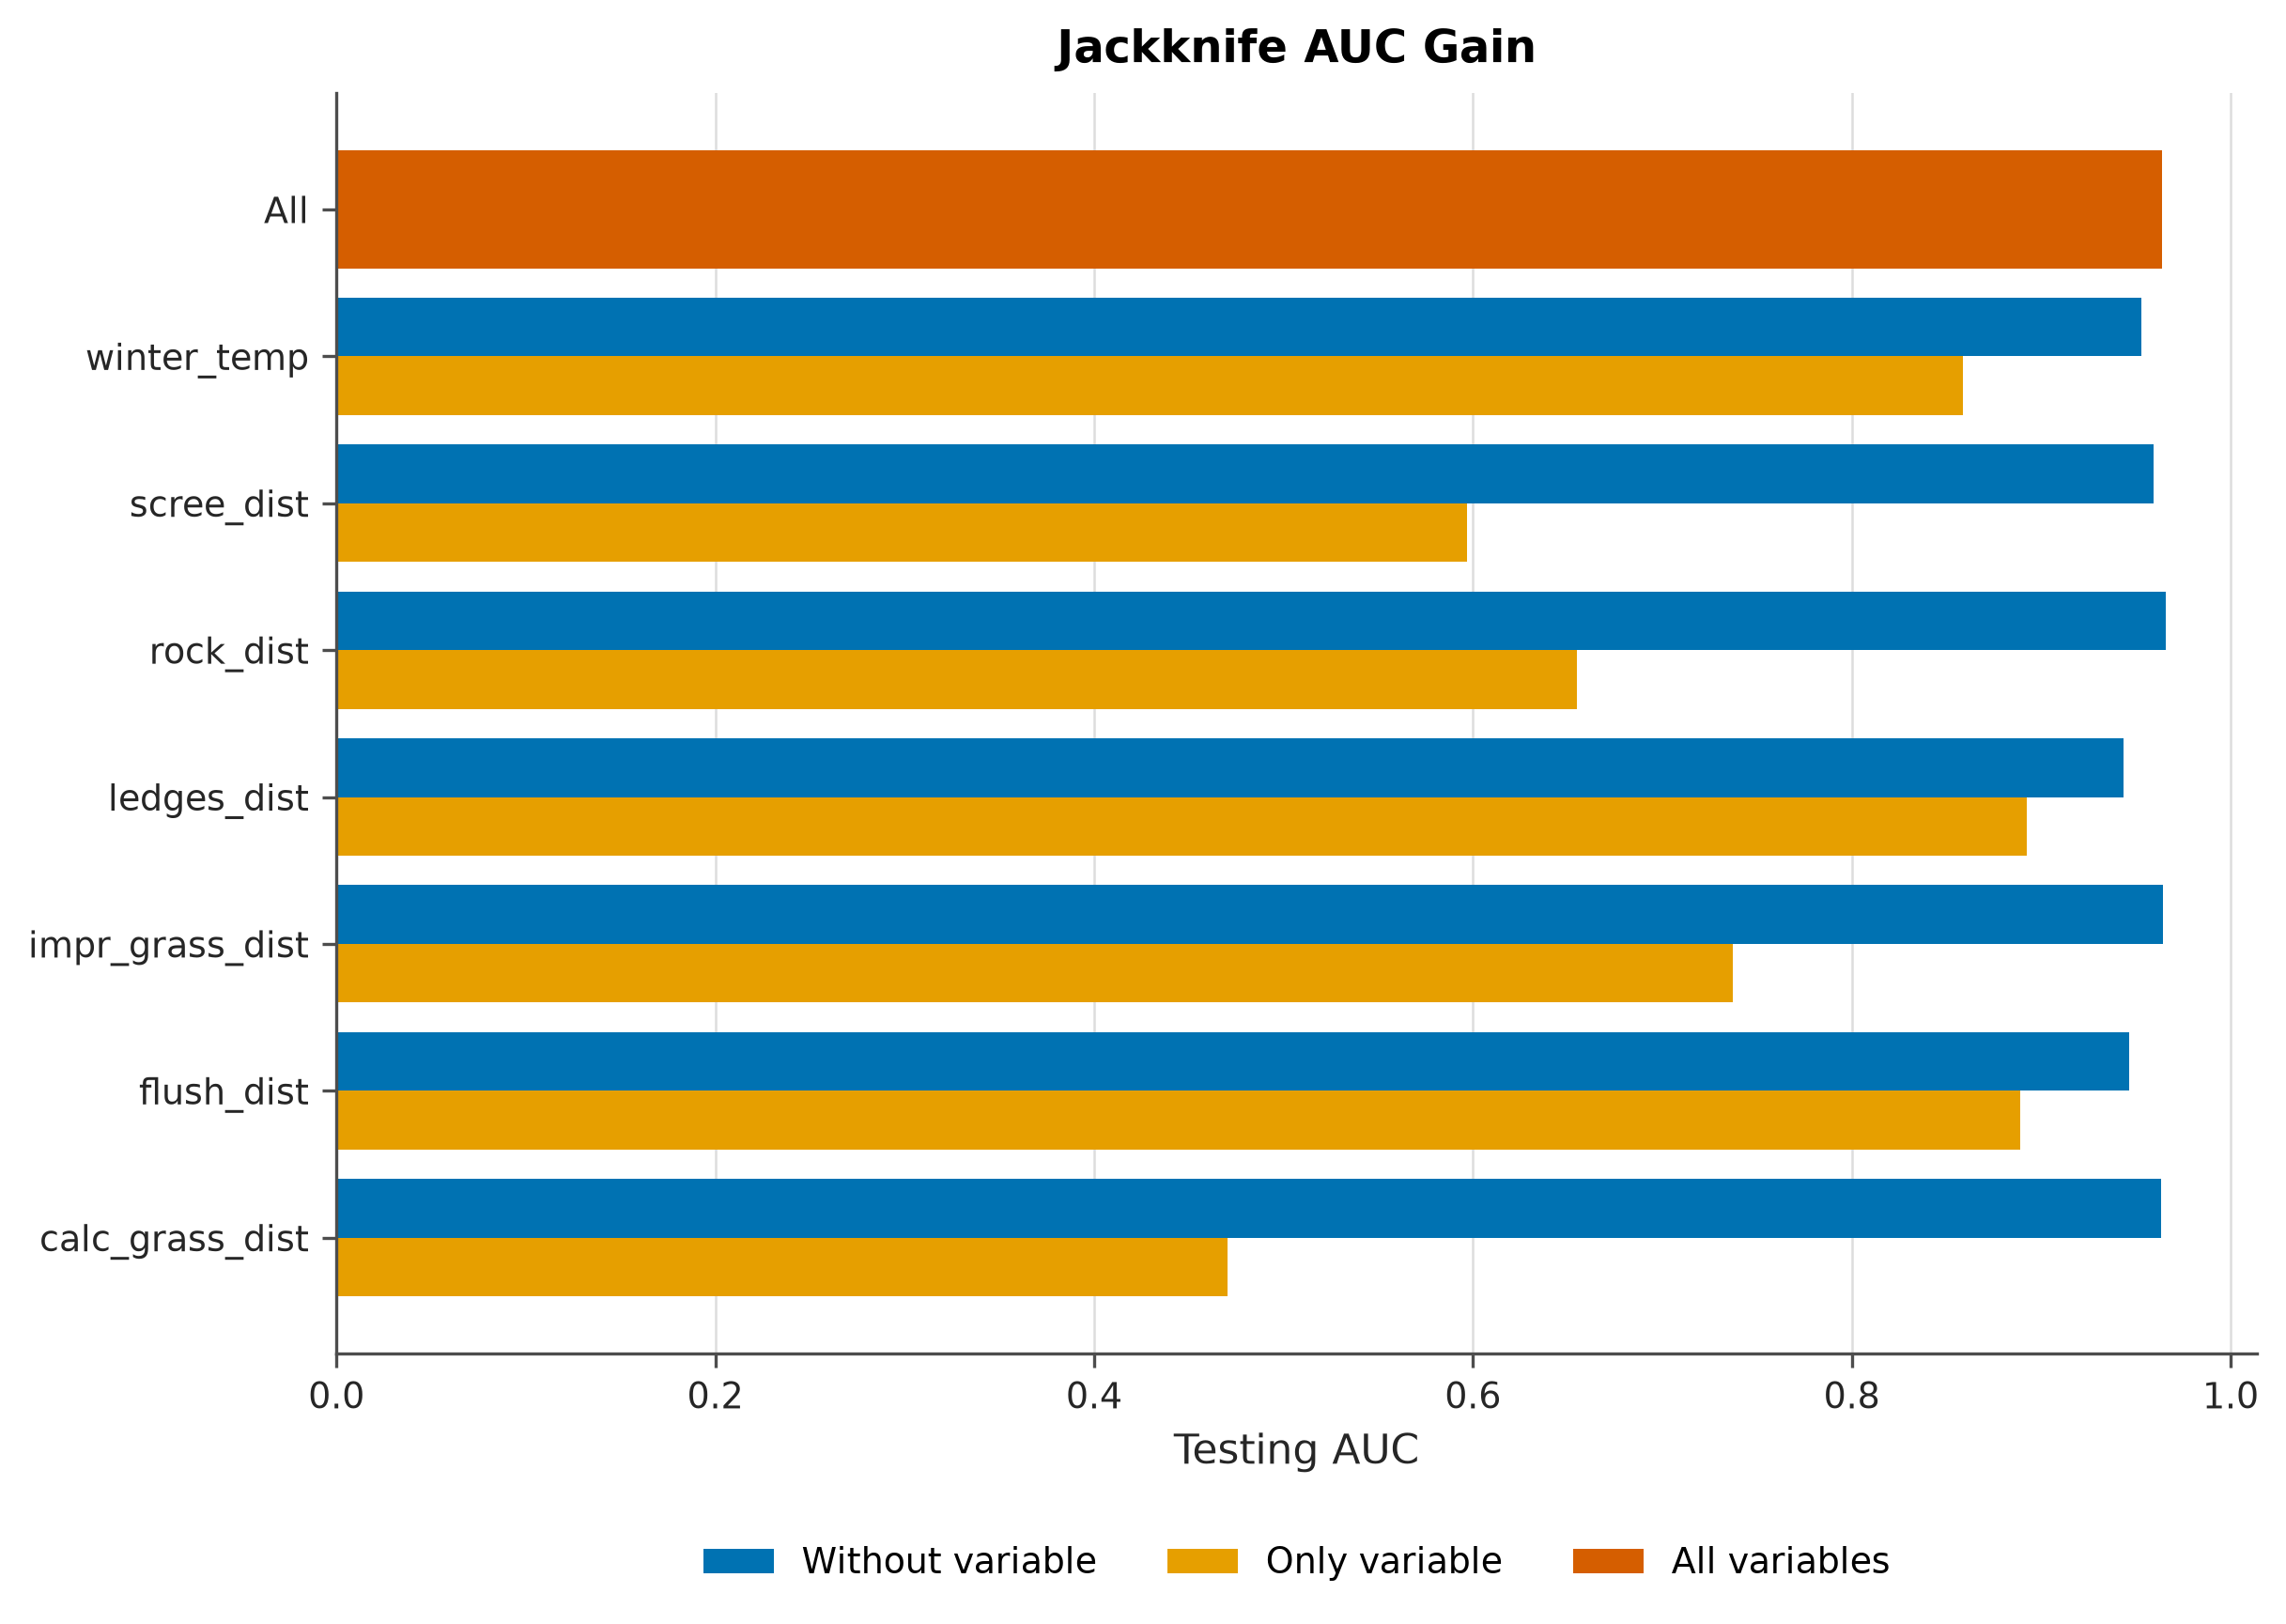

Test AUC with all the variables: 0.964


,roc_test_acc_leave_var_out,roc_test_acc_only_var
calc_grass_dist,0.963,0.470
flush_dist,0.946,0.889
impr_grass_dist,0.964,0.737
ledges_dist,0.943,0.893
rock_dist,0.966,0.655
scree_dist,0.959,0.597
winter_temp,0.953,0.859


In [23]:
jk_df = species_distribution.sklearn_jackknife_var_importance(
    est_cls_obj=make_lr_mdl(**mdl_params),
    train_vec_file=train_std_gdf,
    train_vec_lyr=None,
    test_vec_file=test_std_gdf,
    test_vec_lyr=None,
    analysis_vars=analysis_vars,
    out_var_importance_file=os.path.join(out_dir, "lr_jackknife_var_importance.csv"),
    out_importance_auc_plot=os.path.join(plots_dir, "lr_jackknife_auc.png"),
    cls_col="clsid",
    use_pbar=False,
)
display(Image(filename=os.path.join(plots_dir, "lr_jackknife_auc.png"), width=700))
print(f"Test AUC with all the variables: {lr_metrics['auc']:.3f}")
jk_df[["roc_test_acc_leave_var_out", "roc_test_acc_only_var"]].round(3)

On their own, the distances to ledges (AUC 0.893) and to flushes (0.889) and winter temperature (0.859) carry most information; the distance to improved grassland is weaker (0.737), rock (0.655) and scree (0.597) carry little, and calcareous grassland none (0.470, no better than random).

Leaving a variable out shows what *only it* contributes. The AUC falls most without ledges (0.964 → 0.943), flushes (0.946) and temperature (0.953): each carries information the others do not. Removing improved grassland, calcareous grassland or scree changes the AUC by less than 0.01, and removing rock slightly *increases* it (0.966). Improved grassland is an informative variable on its own but **redundant**: the information it carries (low, warm valleys) is already in winter temperature. With 11 test presences, differences of less than about 0.01 are within the noise.

### 13.3 SHAP

SHAP (SHapley Additive exPlanations) splits each prediction into a contribution from each variable: the SHAP values of a sample add up to the difference between its prediction and the average prediction. The **summary plot** has one row per variable (most important at the top, by mean |SHAP|) and one dot per training sample: its position is the variable's contribution to that sample's prediction, and its colour is the value of the variable (red high, blue low), so the plot shows both the size and the direction of each effect.

For a linear model, SHAP's `LinearExplainer` is exact and fast, and works on the **log-odds** scale, the scale on which the model is additive. It explains the inputs of the logistic regression itself, i.e. the seven variables **and** `winter_temp_sq`, so temperature's effect is split between two rows. We therefore explain the logistic regression step of the pipeline (`lr_mdl[-1]`) with the training table after the pipeline's transformer has added the squared term.

This needs the optional `shap` package; if it is not installed the step is skipped.

/Users/pfb/miniconda3/envs/osgeo_gee_env_v6/lib/python3.14/site-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


Estimating transforms:   0%|          | 0/1000 [00:00<?, ?it/s]

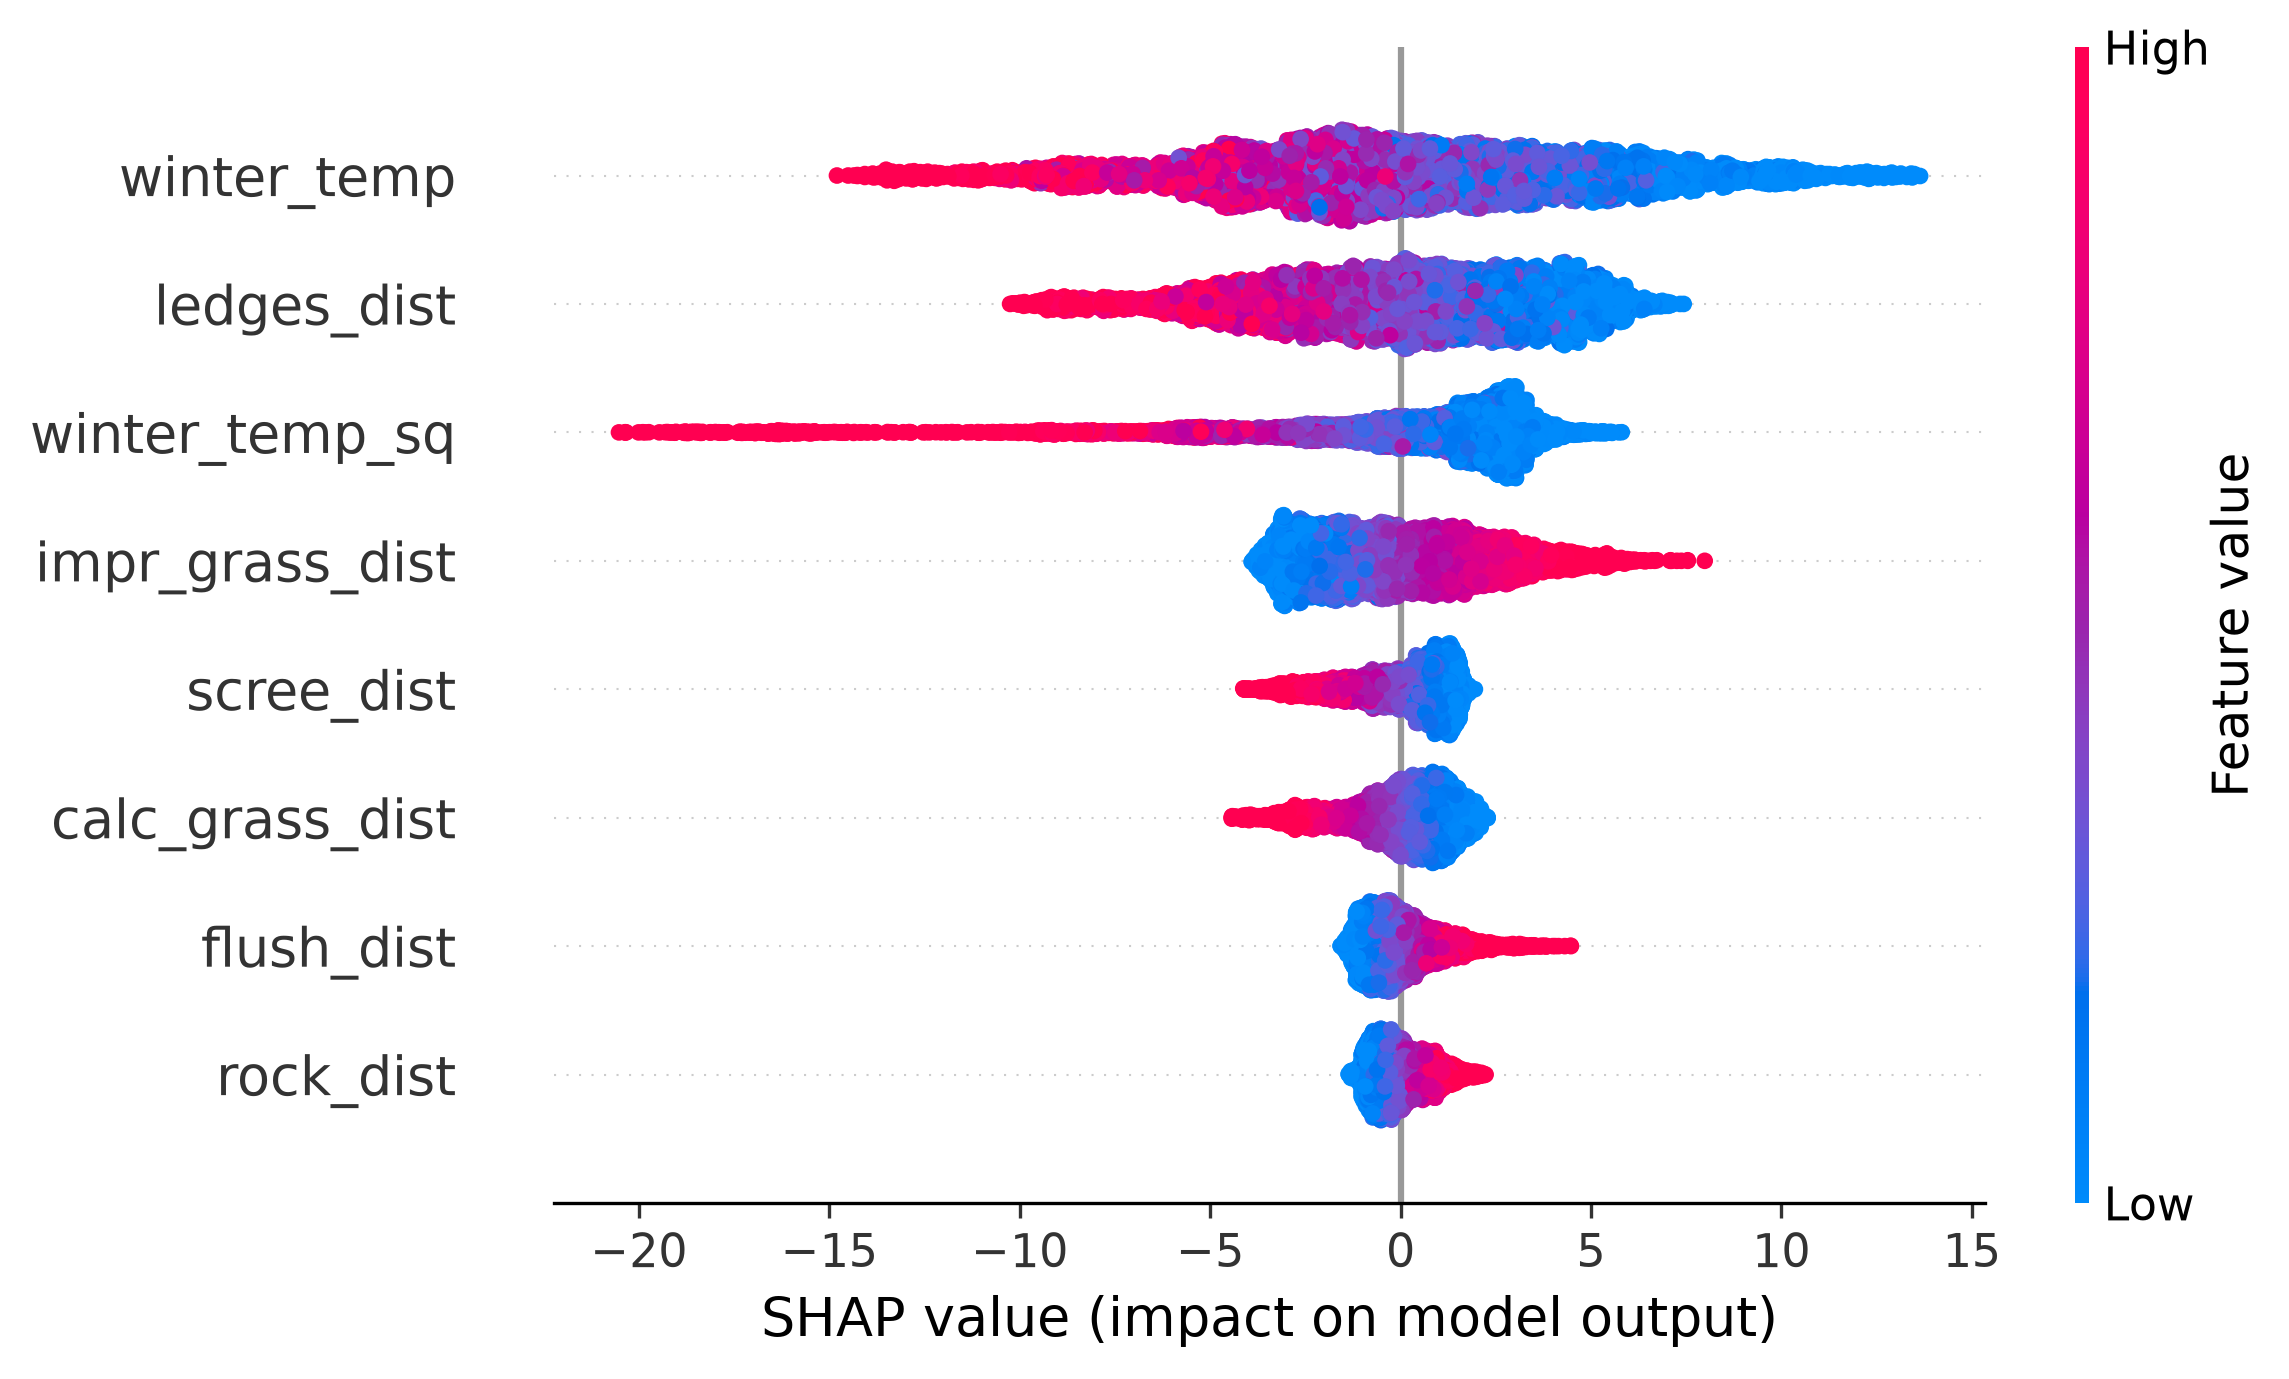

In [24]:
shap_vars = analysis_vars + ["winter_temp_sq"]
if importlib.util.find_spec("shap") is not None:
    train_sq_gdf = add_quadratic_temp(train_std_gdf)
    species_distribution.shap_sklearn_mdl_explainer(
        est_cls_obj=lr_mdl[-1],
        train_vec_file=train_sq_gdf,
        train_vec_lyr=None,
        analysis_vars=shap_vars,
        shap_summary_plot=os.path.join(plots_dir, "lr_shap_summary.png"),
        shap_depend_plots_dir=os.path.join(plots_dir, "lr_shap_dependence"),
        use_tree_explainer=False,
        use_linear_explainer=True,
    )
    display(Image(filename=os.path.join(plots_dir, "lr_shap_summary.png"), width=650))
else:
    print("The shap package is not installed, so the SHAP analysis is skipped.")

The summary plot ranks winter temperature, the distance to ledges and the squared temperature term at the top, and shows the expected directions: high temperatures (red) and large distances to ledges (red) push the prediction down. But some rows look odd: calcareous grassland and improved grassland have a large spread of SHAP values even though their coefficients are almost zero (−0.04 and 0.13), and scree appears with high values pushing the prediction *down*, although its coefficient is positive.

The reason is the type of SHAP values: rsgispy's `shap_sklearn_mdl_explainer` uses `LinearExplainer` with `feature_perturbation="correlation_dependent"`, which accounts for the correlations between the variables and **shares the effect of a variable with the variables correlated with it**. Improved grassland is correlated with temperature (r = −0.66), so it receives part of temperature's effect; scree is correlated with ledges, so it receives part of the ledge effect. The more common *interventional* SHAP values of a linear model are simply each coefficient × (value − mean value), which we can calculate directly from the model; they show what the model itself does with each variable and, for a linear model, are a straight line in each variable by construction. The next cell compares the two.

In [25]:
train_sq_x = add_quadratic_temp(train_std_gdf[analysis_vars])
interv_shap = (train_sq_x - train_sq_x.mean()) * lr_mdl[-1].coef_[0]
shap_cmp_df = pandas.DataFrame({"interventional": interv_shap.abs().mean()})
if importlib.util.find_spec("shap") is not None:
    import shap

    corr_dep_shap = shap.LinearExplainer(
        lr_mdl[-1], train_sq_x, feature_perturbation="correlation_dependent"
    )(train_sq_x)
    shap_cmp_df["correlation-dependent"] = numpy.abs(corr_dep_shap.values).mean(axis=0)
shap_cmp_df["coefficient"] = lr_mdl[-1].coef_[0]
shap_cmp_df.index.name = "mean |SHAP| (log-odds)"
shap_cmp_df.to_csv(os.path.join(out_dir, "lr_shap_mean_abs.csv"))
shap_cmp_df.sort_values("interventional", ascending=False).round(3)

/Users/pfb/miniconda3/envs/osgeo_gee_env_v6/lib/python3.14/site-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


Estimating transforms:   0%|          | 0/1000 [00:00<?, ?it/s]

,interventional,correlation-dependent,coefficient
mean |SHAP| (log-odds),,,
winter_temp,5.062,4.231,-6.218
ledges_dist,3.497,3.005,-4.227
winter_temp_sq,2.465,2.846,-2.676
scree_dist,1.500,0.925,1.826
flush_dist,0.750,0.731,0.945
rock_dist,0.371,0.600,-0.443
impr_grass_dist,0.109,1.918,0.130
calc_grass_dist,0.033,1.119,-0.042


The two kinds of SHAP value answer different questions:

* **Interventional** (what the model does): temperature and its square, ledges, then scree and flushes; improved and calcareous grassland are essentially unused by the fitted model. Scree's contribution is real in the model, but it is the collinearity artefact seen in the response curves.
* **Correlation-dependent** (how the prediction relates to each variable, given the correlations in the data): improved grassland rises to fourth place (it is a stand-in for the valleys), and calcareous grassland gets a share although the model ignores it.

Neither is wrong, but they must not be confused. For "which variables does the model use?", use the interventional values (and the coefficients); for "how is the prediction associated with each variable in this landscape?", the correlation-dependent values. Both are on the **log-odds** scale, where the model is additive: a SHAP value of −5 multiplies the odds of suitability by e⁻⁵ ≈ 0.007.

### 13.4 Sobol Sensitivity Analysis

A Sobol sensitivity analysis (using the `SALib` package) samples every variable over its training range and decomposes the **variance of the predicted suitability** into contributions:

* **S1** (first order): the share of the variance due to the variable alone;
* **ST** (total order): its share including all its interactions with the other variables; ST − S1 measures how much the variable acts through interactions;
* **S2** (second order): the share due to the interaction of each pair.

Three things to keep in mind when reading them:

1. The pipeline is analysed as a whole, with `winter_temp` and its square varied together, so temperature has one set of indices.
2. The analysis is on the **probability** scale. Even though this logistic regression has no interaction terms (it is additive on the log-odds scale), the S-shaped logistic link creates interactions on the probability scale: a change in one variable has a large effect on the probability only where the others put the prediction in the steep middle of the S-curve. So **ST > S1 does not mean an ecological interaction** here.
3. SALib samples each variable independently and uniformly over its range, including combinations that never occur in the landscape (e.g. the warmest valley temperature right next to a species-rich ledge). The indices describe the model's response surface over the training ranges, not how much each variable explains of the actual map.

`n_samples` should be a power of 2; the model is evaluated `n_samples × (2 × n_vars + 2)` times (here 1024 × 16), and the confidence intervals (`*_conf`) show whether that was enough.

calc_grass_dist Range:	(-1.3740436508556557 - 3.630011875222729)
flush_dist Range:	(-1.346681105295006 - 4.714882643026467)
impr_grass_dist Range:	(-1.51565710620492 - 2.995774730255979)
ledges_dist Range:	(-1.567734096828793 - 2.818119209626168)
rock_dist Range:	(-1.526694759159994 - 3.43574410486953)
scree_dist Range:	(-1.2370179964047996 - 3.2003488915161715)
winter_temp Range:	(-1.8555286247008138 - 2.804297434072814)


,ST,ST_conf,S1,S1_conf
ledges_dist,0.633,0.077,0.257,0.076
winter_temp,0.630,0.088,0.230,0.059
scree_dist,0.184,0.041,0.031,0.041
flush_dist,0.096,0.024,0.021,0.029
rock_dist,0.015,0.004,0.003,0.010
impr_grass_dist,0.001,0.000,0.001,0.003
calc_grass_dist,0.000,0.000,0.000,0.001


Largest second order (pairwise interaction) indices:


,S2,S2_conf
"(ledges_dist, winter_temp)",0.263,0.118
"(ledges_dist, scree_dist)",0.043,0.121
"(scree_dist, winter_temp)",0.034,0.070
"(ledges_dist, rock_dist)",0.026,0.114
"(rock_dist, winter_temp)",0.008,0.024


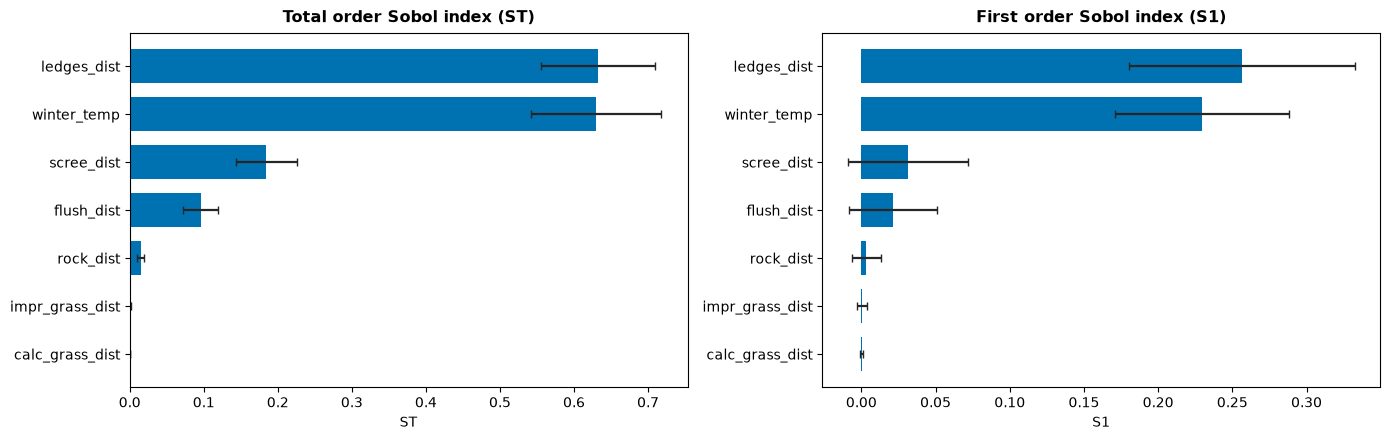

In [26]:
if importlib.util.find_spec("SALib") is not None:
    total_si, first_si, second_si = species_distribution.salib_sklearn_mdl_sensitivity(
        est_cls_obj=lr_mdl,
        train_vec_file=train_std_gdf,
        train_vec_lyr=None,
        analysis_vars=analysis_vars,
        n_samples=1024,
        sobol_overall_file=os.path.join(out_dir, "lr_sobol_total.csv"),
        sobol_first_file=os.path.join(out_dir, "lr_sobol_first_order.csv"),
        sobol_second_file=os.path.join(out_dir, "lr_sobol_second_order.csv"),
        rnd_seed=42,
    )
    total_si.to_csv(os.path.join(out_dir, "lr_sobol_ST.csv"), index_label="variable")
    order = total_si["ST"].sort_values(ascending=False).index
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
    rsgispy.tools.plotting.plot_feature_importance_bars(
        list(order), total_si.loc[order, "ST"], errors=total_si.loc[order, "ST_conf"],
        title="Total order Sobol index (ST)", xlabel="ST", ax=axs[0],
    )
    rsgispy.tools.plotting.plot_feature_importance_bars(
        list(order), first_si.loc[order, "S1"], errors=first_si.loc[order, "S1_conf"],
        title="First order Sobol index (S1)", xlabel="S1", ax=axs[1],
    )
    fig.tight_layout()
    display(pandas.concat([total_si, first_si], axis=1).loc[order].round(3))
    print("Largest second order (pairwise interaction) indices:")
    display(second_si.sort_values("S2", ascending=False).head(5).round(3))
else:
    print("The SALib package is not installed, so the Sobol analysis is skipped.")

Temperature and the distance to ledges dominate: each has a total index (ST) of 0.63, with first order indices (S1) of 0.23–0.26, followed by scree (ST 0.18) and flushes (0.10); rock, improved and calcareous grassland contribute almost nothing. The S1 values add up to only about 0.54, and the largest pairwise interaction is ledges × temperature (S2 = 0.26, with a wide interval of ±0.12).

Do not read this as an ecological interaction found in the data: this logistic regression has no interaction term. It is the logistic link at work: the model is additive on the log-odds scale, so the odds of suitability *multiply*; the predicted suitability is high only where the temperature **and** the distance to ledges are both favourable, and a change in one matters only where the other is favourable. That "both are needed" behaviour is built into the model's form.

Scree's ST (0.18) is larger than its jackknife or SHAP importance suggests: SALib varies scree independently of ledges, over combinations (far from scree but next to a ledge) that are rare in the landscape, which exercises the collinearity artefact of its coefficient. The confidence intervals (about ±0.08 for the largest indices) are acceptable for ranking the variables; more samples would be needed for precise values.

### 13.5 What Does the Model Say About the Snowdon Beetle's Niche?

Bringing the four tools together, the logistic regression describes the Snowdon beetle's niche, as seen through our variables, as:

* **close to species-rich ledges** — the most consistent result of every method (strongest on its own in the jackknife, the largest drop when removed, top two in SHAP and Sobol): suitability falls by half at about 1 km and to near 0 at 2 km from a mapped ledge. This matches the beetle's dependence on thyme growing on ledges out of reach of grazing animals.
* **within a narrow, cool band of winter temperature** — about 2.5–3.2 °C, optimum 2.8 °C, i.e. roughly 500–850 m with an optimum near 700 m, matching the altitudes of the 2015–2016 NRW records (555–827 m, mean 738 m). Because temperature and elevation are interchangeable here, this is equally a description of the altitudinal band of the beetle.
* **away from wet flushes and improved pasture** — dry, free-draining, unimproved ground. The flush effect is robust in the jackknife, but its interpretation (thyme avoiding wet ground, or a mapping effect on crags) cannot be settled with these data. The improved grassland effect is largely shared with temperature.

**Where the methods disagree, and why.** Improved grassland is informative on its own (jackknife, correlation-dependent SHAP) but redundant once temperature is in the model (leave-one-out jackknife, interventional SHAP, Sobol): it is a correlated stand-in. Scree has a counter-intuitive positive coefficient that inflates its Sobol index; it is a collinearity artefact with ledges, not avoidance of scree. Calcareous grassland and rock exposures carry little or no information. This follows the guide's advice: use the jackknife for "what can I remove?", the response curves and SHAP for "how does suitability change?", and the Sobol indices for "what drives the variation of the prediction?", and look for the reason (usually correlation, or interactions created by the model) when they disagree.

**Limits of the inference.** There are only 34 presences (23 for training), all from a few crags, and several are old or imprecise. The variables are **proxies**: the distance to a mapped ledge stands for the presence of thyme and of refuges from grazing, and temperature stands for everything that changes with altitude. Some of the beetle's habitat is hidden in mosaic polygons, and the records are not corrected for survey effort. The model therefore describes where the beetle has been recorded, not its physiological limits (its fundamental niche).

**Data that would improve the model:** a map of wild thyme (the beetle's only food), grazing pressure (sheep and goat densities, exclosures), geology or soil base status (thyme needs base-rich substrates), aspect and microclimate on the crags, and systematic surveys that record where the beetle was searched for and *not* found (true absences).

## 14. Predict the Suitability Map

`pred_ensemble_sklearn_mdls_prob` applies every member of the spatial ensemble to every valid pixel and writes the **median** suitability as band 1; with `uncertainty=["std", "iqr"]` it adds the standard deviation and interquartile range of the members as bands 2 and 3, which show where the prediction depends on which training data a member saw. `pred_ensemble_sklearn_mdls_cls` writes the **proportion of members predicting presence** (each at its default 0.5 cut-off), another measure of agreement. `normalise_data=True` standardises the rasters with the training means and standard deviations.

In [27]:
lr_prob_img = os.path.join(out_dir, "Snowdon_Beetle_lr_sdm_prob.tif")
species_distribution.pred_ensemble_sklearn_mdls_prob(
    lr_mdls, valid_msk_img, 1, env_vars, analysis_vars, lr_prob_img,
    gdalformat="GTIFF", tmp_dir=tmp_dir, normalise_data=True, calc_stats=True,
    uncertainty=["std", "iqr"], use_pbar=False,
)
lr_agree_img = os.path.join(out_dir, "Snowdon_Beetle_lr_sdm_agreement.tif")
species_distribution.pred_ensemble_sklearn_mdls_cls(
    lr_mdls, valid_msk_img, 1, env_vars, analysis_vars, lr_agree_img,
    gdalformat="GTIFF", tmp_dir=tmp_dir, normalise_data=True, calc_stats=True,
    use_pbar=False,
)

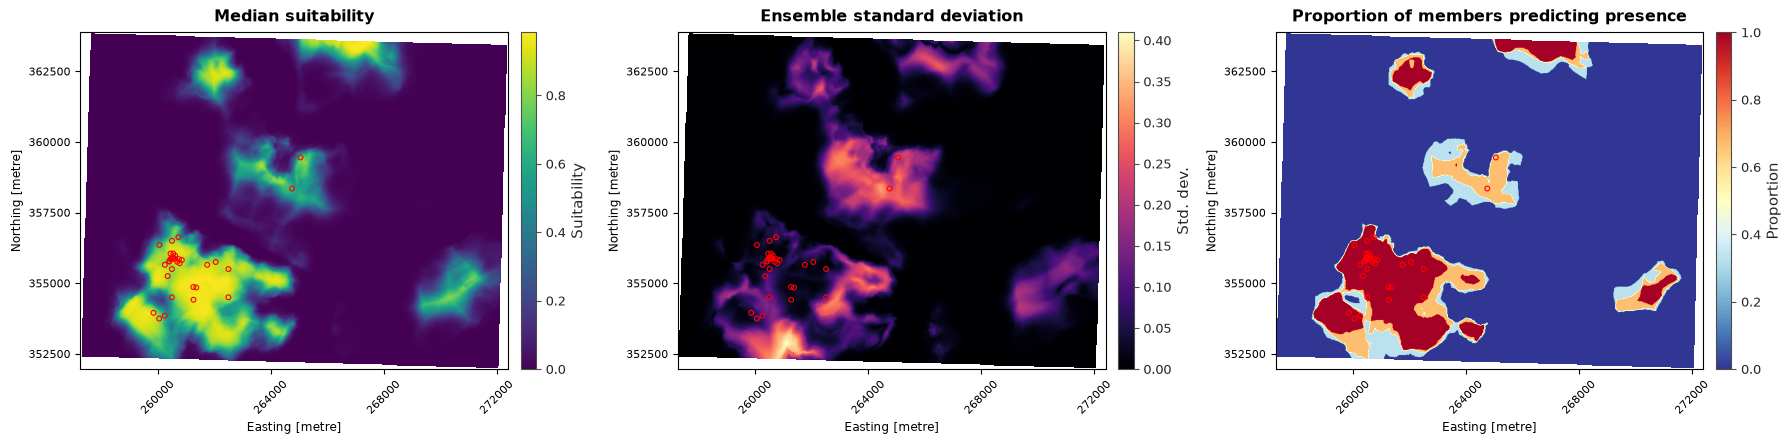

In [28]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
map_specs = [
    (lr_prob_img, 1, "Median suitability", "viridis", "Suitability"),
    (lr_prob_img, 2, "Ensemble standard deviation", "magma", "Std. dev."),
    (lr_agree_img, 1, "Proportion of members predicting presence", "RdYlBu_r", "Proportion"),
]
for ax, (img, band, title, cmap, label) in zip(axs, map_specs):
    rsgispy.mapping.raster.create_raster_cmap_img_map(
        ax, input_img=img, img_band=band, title_str=title, cmap_name=cmap,
        show_colour_bar=True, cbar_label=label, show_scale_bar=False,
    )
    pres_gdf.plot(ax=ax, facecolor="none", edgecolor="red", markersize=12, linewidth=0.8)
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()

The median suitability is highest around the cluster of records on Yr Wyddfa in the south-west of the study area, with smaller suitable areas in the centre (around the two isolated records), in the north and in the east. Most of the study area, including all the valleys, has a suitability near 0.

The ensemble standard deviation is highest at the edges of the suitable areas and over the central and eastern patches, where the three members (each trained without one group of blocks) disagree; the agreement map shows the same thing: the core of the Yr Wyddfa area is predicted present by all three members, while the fringes and parts of the other patches are predicted by only one or two. The northern and eastern patches have no records: they are either unsurveyed suitable habitat (candidate sites for a survey) or unsuitable for reasons the model does not know about (e.g. acidic rocks without thyme).

### 14.1 Threshold the Map: Where Is the Habitat Suitable?

Many uses (the area of suitable habitat, planning surveys) need a binary map. The threshold should come from the data, not be fixed at 0.5. Two common choices:

* **maximum TSS** on the test set: balances omission (presences predicted unsuitable) and commission errors; `calc_binary_threshold(..., method="max_tss")`;
* **10th percentile training presence**: the suitability exceeded at 90 % of the training presences, a conservative choice for presence-only data that accepts 10 % omission.

`calc_boyce_index_from_raster` calculates the Boyce index of the final map with all 34 presences against every valid pixel as background (in-sample for the training presences, so a little optimistic).

In [29]:
ens_train_probs = numpy.median(
    [species_distribution.get_positive_class_probs(mdl, train_std_gdf[analysis_vars]) for mdl in lr_mdls],
    axis=0,
)
lr_thres = {
    "max TSS": species_distribution.calc_binary_threshold(test_y, ens_test_probs, method="max_tss"),
    "10th percentile training presence": float(
        numpy.percentile(ens_train_probs[train_std_gdf["clsid"] == 1], 10)
    ),
}
with rasterio.open(lr_prob_img) as src:
    prob_arr = src.read(1)
    pxl_km2 = abs(src.res[0] * src.res[1]) / 1e6
valid = prob_arr >= 0
thres_rows = []
for name, thres in lr_thres.items():
    test_bin = (ens_test_probs >= thres).astype(int)
    thres_rows.append(
        {
            "threshold": name,
            "value": thres,
            "test sensitivity": test_bin[test_y == 1].mean(),
            "test specificity": 1 - test_bin[test_y == 0].mean(),
            "suitable area (km²)": (prob_arr[valid] >= thres).sum() * pxl_km2,
            "% of study area": 100 * (prob_arr[valid] >= thres).mean(),
        }
    )
rsgispy.tools.jsonio.write_dict_to_json(lr_thres, os.path.join(out_dir, "lr_thresholds.json"))
display(pandas.DataFrame(thres_rows).round(3))

boyce_res = species_distribution.calc_boyce_index_from_raster(
    lr_prob_img, presences_vec_file, presences_vec_lyr,
    plot_file=os.path.join(plots_dir, "lr_boyce_map.png"), use_pbar=False,
)
print(f"Boyce index of the map: {boyce_res['boyce']:.3f}")

,threshold,value,test sensitivity,test specificity,suitable area (km²),% of study area
0,max TSS,0.663,1.000,0.908,15.193,8.928
1,10th percentile training presence,0.671,0.909,0.909,14.919,8.767


Boyce index of the map: 0.761


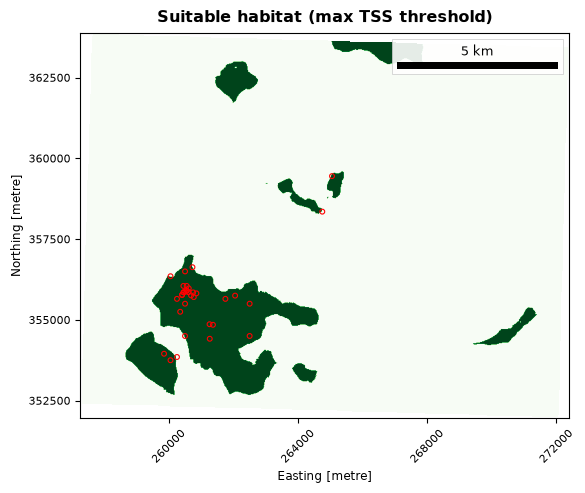

In [30]:
lr_bin_img = os.path.join(out_dir, "Snowdon_Beetle_lr_sdm_bin.tif")
band_defs = [rsgispy.imagecalc.maths.BandDefn("prob", lr_prob_img, 1)]
rsgispy.imagecalc.maths.band_maths(
    lr_bin_img,
    f"prob < 0 ? 255 : (prob >= {lr_thres['max TSS']} ? 1 : 0)",
    band_defs,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
    no_data_val=255,
    use_pbar=False,
)
fig, ax = plt.subplots(figsize=(7, 5))
rsgispy.mapping.raster.create_raster_cmap_img_map(
    ax, input_img=lr_bin_img, img_band=1, title_str="Suitable habitat (max TSS threshold)",
    cmap_name="Greens", show_colour_bar=False,
)
pres_gdf.plot(ax=ax, facecolor="none", edgecolor="red", markersize=12, linewidth=0.8)
ax.tick_params(axis="x", labelrotation=45)

The two thresholds are almost the same here (0.663 for maximum TSS, 0.671 for the 10th percentile training presence). They are far from 0.5 because of `class_weight="balanced"`, which scales the predictions as if presences and pseudo-absences were equally common: a reminder that 0.5 has no special meaning. At the maximum TSS threshold, about 15 km² (8.9 % of the study area) is predicted suitable, and all 11 test presences fall in it (sensitivity 1.0, specificity 0.908). With 11 test presences, the threshold is itself uncertain.

The Boyce index of the map (0.761, all 34 presences against every valid pixel) is lower than that of the test points (0.889), because the map's background is every pixel rather than the pseudo-absences, but still clearly positive: presences are increasingly over-represented as the predicted suitability rises.

## 15. Where Does the Map Extrapolate?

A model has only seen the conditions in its training data. Elsewhere, its predictions come from how the algorithm extends the fitted curves (for a logistic regression with a quadratic term, the parabola keeps falling; for the linear terms the S-curve keeps going), not from data. Two maps show where this happens:

* **MESS** (multivariate environmental similarity surface, `calc_mess`): negative where at least one variable is outside the range of the training samples; `out_mod_var_img` records which variable is the most dissimilar at each pixel;
* **ExDet** (`calc_exdet`): band 1 (NT1) is like MESS; band 2 (NT2) finds **combinations** of values that were not seen together in the training data even though each is within its range (NT2 > 1).

The reference samples are the training samples with their raw (un-standardised) values.

MESS < 0 (outside the training range): 0.08 % of the study area
NT2 > 1 (novel combinations):          0.02 % of the study area


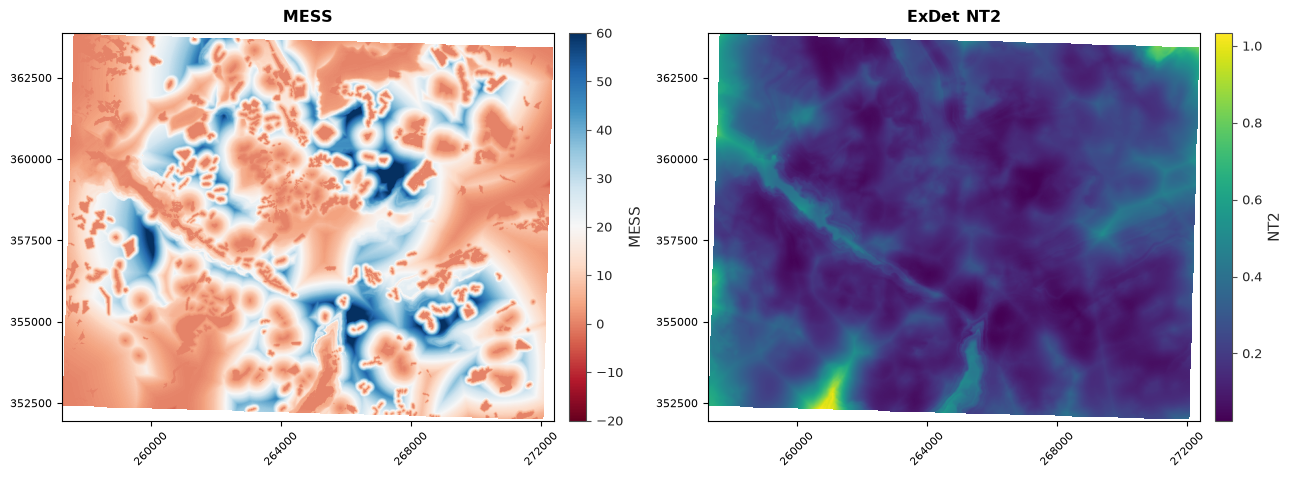

In [31]:
mess_img = os.path.join(out_dir, "lr_mess.tif")
mess_mod_img = os.path.join(out_dir, "lr_mess_mod_var.tif")
species_distribution.calc_mess(
    train_gdf, None, valid_msk_img, 1, env_vars, analysis_vars, mess_img,
    out_mod_var_img=mess_mod_img, use_pbar=False,
)
exdet_img = os.path.join(out_dir, "lr_exdet.tif")
species_distribution.calc_exdet(
    train_gdf, None, valid_msk_img, 1, env_vars, analysis_vars, exdet_img, use_pbar=False,
)
with rasterio.open(mess_img) as src:
    mess_arr = src.read(1, masked=True)
with rasterio.open(exdet_img) as src:
    nt2_arr = src.read(2, masked=True)
print(f"MESS < 0 (outside the training range): {100 * (mess_arr < 0).mean():.2f} % of the study area")
print(f"NT2 > 1 (novel combinations):          {100 * (nt2_arr > 1).mean():.2f} % of the study area")

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
rsgispy.mapping.raster.create_raster_cmap_img_map(
    axs[0], input_img=mess_img, img_band=1, title_str="MESS", cmap_name="RdBu",
    show_colour_bar=True, cbar_label="MESS", norm_img_vals=True, norm_vmin=-20, norm_vmax=60,
    show_scale_bar=False,
)
rsgispy.mapping.raster.create_raster_cmap_img_map(
    axs[1], input_img=exdet_img, img_band=2, title_str="ExDet NT2", cmap_name="viridis",
    show_colour_bar=True, cbar_label="NT2", show_scale_bar=False,
)
for ax in axs:
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()

Only 0.08 % of the study area has a negative MESS, and 0.02 % has NT2 > 1. Under current conditions the map hardly extrapolates at all, because the 7000 training pseudo-absences sample the whole study area, so almost every pixel is inside the range of the training data. (In the map, MESS is close to 0, orange, wherever at least one variable is near the edge of its range, e.g. on or right next to a habitat patch, where the distance is 0, and highest, blue, where every variable is near its median.) MESS and ExDet matter much more when the model is applied to a different time or place, as in the next section.

## 16. Optional: Projecting to a Warmer Climate

The NRW surveys suggest the beetle may be retreating upslope. What does the model imply if winter temperatures rise? We make scenario temperature rasters with `band_maths`, swap each into a copy of `env_vars` with `copy_env_vars_for_scenario` (which keeps the training normalisation coefficients), predict with the same ensemble, threshold with the **same** (max TSS) threshold, and compare the current and scenario binary maps with `calc_range_change` (1 absent, 2 lost, 3 gained, 4 stable). MESS shows where each scenario takes the model outside its training data.

First, how does winter temperature change with altitude in this raster? This tells us what a warming of 1 °C means here.

In [32]:
lapse_slope, lapse_icpt = numpy.polyfit(samples_gdf["elevation"], samples_gdf["winter_temp"], 1)
print(f"Winter temperature changes by {lapse_slope * 100:.2f} °C per 100 m of altitude")
for temp in [2.5, 2.8, 3.2]:
    print(f"  {temp} °C is at about {(temp - lapse_icpt) / lapse_slope:.0f} m")

Winter temperature changes by -0.20 °C per 100 m of altitude
  2.5 °C is at about 850 m
  2.8 °C is at about 699 m
  3.2 °C is at about 498 m


In this raster, winter temperature falls by only about 0.2 °C per 100 m of altitude, about a third of a typical lapse rate in the British uplands (around 0.6 °C per 100 m): its whole range is 2.5–4.5 °C over 1000 m of altitude, so it is probably a smoothed (coarse-resolution) climate surface. Two consequences:

* the temperature limits of the response curve translate into altitudes (about 500–850 m, optimum about 700 m) that match the NRW records well, but the temperatures themselves should not be read as the beetle's physiological limits;
* a uniform warming of 0.5 °C in this raster moves every temperature by the equivalent of about 250 m of altitude, and 1 °C by about 500 m. Real warming of the same size would shift temperatures by far less altitude, so the scenarios below **exaggerate** the change. We use them to show the workflow and the behaviour of the model, not as a forecast.

In [33]:
scen_rows = []
for warming in [0.5, 1.0]:
    tag = f"plus{warming:.1f}".replace(".", "_")
    warm_temp_img = os.path.join(out_dir, f"Mean_Winter_Temp_{tag}.tif")
    rsgispy.imagecalc.maths.band_maths(
        warm_temp_img,
        f"temp == 0 ? 0 : temp + {warming}",
        [rsgispy.imagecalc.maths.BandDefn("temp", env_vars["winter_temp"].file, 1)],
        gdalformat="GTIFF", datatype=rsgispy.TYPE_32FLOAT, no_data_val=0, use_pbar=False,
    )
    warm_env_vars = species_distribution.copy_env_vars_for_scenario(
        env_vars, {"winter_temp": warm_temp_img}
    )
    warm_prob_img = os.path.join(out_dir, f"Snowdon_Beetle_lr_sdm_prob_{tag}.tif")
    species_distribution.pred_ensemble_sklearn_mdls_prob(
        lr_mdls, valid_msk_img, 1, warm_env_vars, analysis_vars, warm_prob_img,
        normalise_data=True, calc_stats=True, use_pbar=False,
    )
    warm_bin_img = os.path.join(out_dir, f"Snowdon_Beetle_lr_sdm_bin_{tag}.tif")
    rsgispy.imagecalc.maths.band_maths(
        warm_bin_img,
        f"prob < 0 ? 255 : (prob >= {lr_thres['max TSS']} ? 1 : 0)",
        [rsgispy.imagecalc.maths.BandDefn("prob", warm_prob_img, 1)],
        gdalformat="GTIFF", datatype=rsgispy.TYPE_8UINT, no_data_val=255, use_pbar=False,
    )
    warm_mess_img = os.path.join(out_dir, f"lr_mess_{tag}.tif")
    species_distribution.calc_mess(
        train_gdf, None, valid_msk_img, 1, warm_env_vars, analysis_vars, warm_mess_img,
        use_pbar=False,
    )
    with rasterio.open(warm_mess_img) as src:
        mess_neg_pct = 100 * float((src.read(1, masked=True) < 0).mean())
    range_img = os.path.join(out_dir, f"lr_range_change_{tag}.tif")
    summary = species_distribution.calc_range_change(
        lr_bin_img, warm_bin_img, range_img, in_msk_img=valid_msk_img, use_pbar=False,
    )
    scen_rows.append(
        {
            "warming (°C)": warming,
            "MESS < 0 (% of area)": mess_neg_pct,
            "current (km²)": summary["current_area"] / 1e6,
            "scenario (km²)": summary["future_area"] / 1e6,
            "lost (km²)": summary["area_lost"] / 1e6,
            "gained (km²)": summary["area_gained"] / 1e6,
            "stable (km²)": summary["area_stable"] / 1e6,
            "net change (%)": summary["pct_net_change"],
        }
    )
scen_df = pandas.DataFrame(scen_rows)
scen_df.to_csv(os.path.join(out_dir, "lr_scenarios.csv"), index=False)
scen_df.round(2)

,warming (°C),MESS < 0 (% of area),current (km²),scenario (km²),lost (km²),gained (km²),stable (km²),net change (%)
0,0.5,6.61,15.19,2.12,13.45,0.38,1.74,-86.02
1,1.0,34.07,15.19,0.00,15.19,0.00,0.00,-100.00


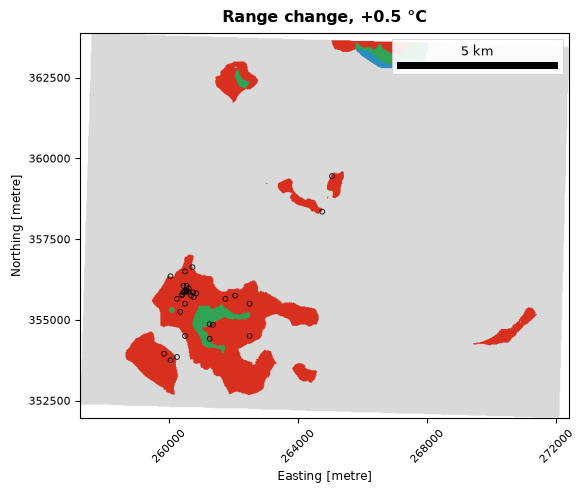

In [34]:
fig, ax = plt.subplots(figsize=(7, 5))
rsgispy.mapping.raster.create_thematic_raster_map(
    ax, input_img=os.path.join(out_dir, "lr_range_change_plus0_5.tif"),
    title_str="Range change, +0.5 °C",
)
pres_gdf.plot(ax=ax, facecolor="none", edgecolor="black", markersize=12, linewidth=0.6)
ax.tick_params(axis="x", labelrotation=45)

With +0.5 °C, the area predicted suitable falls from 15.2 km² to 2.1 km² (−86 %): 13.5 km² is lost, 1.7 km² is stable, and only 0.4 km² is gained. The stable area is the highest, coldest ground around the summit of Yr Wyddfa, just east of the cluster of records, and the small gain is on high ground in the north-east. With +1 °C nothing remains suitable. This is the model's version of the NRW suggestion that the beetle is retreating upslope: with a narrow temperature band near the cold end of what exists in the study area, warming pushes the suitable band off the top of the mountains.

The caveats are as important as the result:

* **Extrapolation.** Under +0.5 °C, 6.6 % of the study area is outside the training range (MESS < 0); under +1 °C, 34 %. There the predictions come from the parabola of the quadratic term continuing downwards, not from data.
* **The temperature–elevation confound.** The model cannot tell whether the beetle needs cool temperatures or something else found high up (less grazing, the crags themselves, or the places that have been searched). If the latter, warming alone would not have this effect.
* **Fixed habitat.** The ledge, scree and other habitat distances are held fixed: thyme and its ledges do not move uphill, and new suitable habitat cannot appear where there are no ledges.
* **The temperature raster** has a weak lapse rate, so these warmings correspond to large altitude shifts (see above).
* **No dispersal, biotic interactions or adaptation** are modelled; the beetle is thought to be flightless (NRW report), so it is unlikely to reach new sites quickly.

The result shows why species of isolated mountain tops are thought to be vulnerable to warming, but a credible projection would need better climate data (e.g. downscaled UKCP18 projections), and ideally a model in which the temperature effect is separated from the effects of altitude and grazing.

## Going Further

* Notebooks 03 and 04 fit **MaxEnt** and a **random forest** to the same presences, background and variables, and notebook 05 compares the three models.
* The rsgispy species distribution modelling guide covers the same workflow with a random forest, and sampling-bias correction with bias grids.
* Try the stricter record filters of notebook 01, or adding the habitats hidden in mosaic polygons, and see how much the response curves and the map change.